### Stage 0.1 - Setup: imports, paths, module and checkpoint settings

In [2]:
# Libraries used in the data build and the feasibility check
import pandas as pd
import numpy as np
import os

# ---- Settings for DDD ----
MODULE = "DDD"                                    # module we are working on
PRES = ["2013J", "2014B", "2014J"]                # same presentations as the RQ1 merged file (2013B excluded)
FOCUS_ACT = "quiz"                                # the activity we look at most closely (confirm at Stage 0.3)
RAW_DIR = r"C:\Users\Disha Sharma\Desktop\Paper_1\DATA"            # folder with the original OULAD CSVs
OUT_DIR = rf"C:\Users\Disha Sharma\Desktop\Paper_1\RQ4\{MODULE}"   # all outputs go here
os.makedirs(OUT_DIR, exist_ok=True)

# ---- Checkpoints in days from the course start: 28 = end of week 4, 56 = end of week 8 ----
CUTOFFS = [28, 56]
EARLY_END, WIN_END = 28, 56      # early period = up to day 28; action window = days 29 to 56

### Stage 0.2 - Load the students: final result plus registration and unregistration dates

In [5]:
# studentInfo: final outcome for every student; studentRegistration: when they registered and left
info = pd.read_csv(os.path.join(RAW_DIR, "studentInfo.csv"))
reg = pd.read_csv(os.path.join(RAW_DIR, "studentRegistration.csv"))

# Keep only this module and its presentations
info = info[(info.code_module == MODULE) & (info.code_presentation.isin(PRES))]
reg = reg[(reg.code_module == MODULE) & (reg.code_presentation.isin(PRES))]

# One row per student (date_unregistration is empty for students who never left)
stu = info.merge(
    reg[['code_presentation', 'id_student', 'date_registration', 'date_unregistration']],
    on=['code_presentation', 'id_student'], how='left')

# Check: should match the RQ1 merged file (4,969 students)
print("students:", len(stu))
print(stu.final_result.value_counts().to_dict())
print(stu.code_presentation.value_counts().to_dict())     # students per presentation

students: 4969
{'Withdrawn': 1818, 'Pass': 1771, 'Fail': 1051, 'Distinction': 329}
{'2013J': 1938, '2014J': 1803, '2014B': 1228}


### Stage 0.3 - Load the activity-type lookup (which page ids are quizzes, forums, etc.)

In [8]:
# vle.csv tells us the activity type of every course page
vle = pd.read_csv(os.path.join(RAW_DIR, "vle.csv"))
vle = vle[(vle.code_module == MODULE) & (vle.code_presentation.isin(PRES))][
    ['id_site', 'code_presentation', 'activity_type']]
print("pages:", len(vle), "| activity types:", sorted(vle.activity_type.unique()))

pages: 1280 | activity types: ['externalquiz', 'forumng', 'glossary', 'homepage', 'oucollaborate', 'oucontent', 'ouwiki', 'resource', 'subpage', 'url']


### Stage 0.4 - Read the big click file in chunks and keep only this module (slowest cell, a few minutes)

In [11]:
# The click file is too big to load at once: read 500,000 rows at a time and keep only this module
parts = []                                      # reset so reruns do not duplicate rows
for i, chunk in enumerate(pd.read_csv(
        os.path.join(RAW_DIR, "studentVle.csv"),
        usecols=['code_module', 'code_presentation', 'id_student', 'id_site', 'date', 'sum_click'],
        chunksize=500_000)):
    chunk = chunk[(chunk.code_module == MODULE) & (chunk.code_presentation.isin(PRES))]
    if not chunk.empty:
        chunk = chunk.merge(vle, on=['id_site', 'code_presentation'], how='left')   # add the activity type
        parts.append(chunk[['code_presentation', 'id_student', 'activity_type', 'date', 'sum_click']])
    if i % 5 == 0:
        print("chunks read:", i + 1)       # progress

clicks = pd.concat(parts, ignore_index=True)
# 'date' = day of the click counted from the start (negative = before the start)
print("click rows:", len(clicks), "| date range:", clicks.date.min(), "to", clicks.date.max())
print("clicks with no activity type (should be about 0):", int(clicks.activity_type.isna().sum()))

chunks read: 1
chunks read: 6
chunks read: 11
chunks read: 16
chunks read: 21
click rows: 1629649 | date range: -25 to 262
clicks with no activity type (should be about 0): 0


### Stage 0.5 - Each student's clicks up to every checkpoint, and who is still enrolled then

In [14]:
FOCUS_ACT = "externalquiz"                       # DDD has no quiz type: change this line to use another activity

keys = ['code_presentation', 'id_student']        # identifies one student
feat = stu[keys + ['final_result', 'date_registration', 'date_unregistration']].copy()

for c in CUTOFFS:
    sub = clicks[clicks.date <= c]                 # clicks up to the checkpoint day
    tot = (sub.groupby(keys).sum_click.sum().rename(f'total_clicks_d{c}').reset_index())
    foc = (sub[sub.activity_type == FOCUS_ACT].groupby(keys).sum_click.sum()
           .rename(f'focus_clicks_d{c}').reset_index())
    feat = feat.merge(tot, on=keys, how='left').merge(foc, on=keys, how='left')
    feat[[f'total_clicks_d{c}', f'focus_clicks_d{c}']] = feat[[f'total_clicks_d{c}', f'focus_clicks_d{c}']].fillna(0)   # no clicks -> 0
    # Still enrolled = registered by then AND not yet unregistered (missing unregistration = never left)
    feat[f'enrolled_d{c}'] = ((feat.date_registration.fillna(-999) <= c) &
                              (feat.date_unregistration.isna() | (feat.date_unregistration > c)))

feat.to_csv(os.path.join(OUT_DIR, f"{MODULE}_early_features.csv"), index=False)
print(feat.shape)

(4969, 11)


### Stage 1.1 - Can we still reach at-risk students, and does early activity separate outcomes?

In [17]:
def banded(s):
    # Bands: exactly 0, then quartile bands of students who had some activity
    nz = s[s > 0]
    qs = sorted({int(round(x)) for x in nz.quantile([.25, .5, .75])} - {0}) if len(nz) else []
    return pd.cut(s, bins=[-1, 0] + qs + [np.inf])

def summarize(df, band_col):
    # Per band: students, % ending Pass/Distinction, Fail, Withdrawn
    return df.groupby(band_col, observed=True).final_result.agg(
        n='size',
        pct_pass=lambda s: s.isin(['Pass', 'Distinction']).mean() * 100,
        pct_fail=lambda s: (s == 'Fail').mean() * 100,
        pct_withdrawn=lambda s: (s == 'Withdrawn').mean() * 100).round(1)

total_w = (feat.final_result == 'Withdrawn').sum()
total_f = (feat.final_result == 'Fail').sum()
for c in CUTOFFS:
    e = feat[feat[f'enrolled_d{c}']].copy()            # students still enrolled at this checkpoint
    print(f"\n=== Checkpoint: day {c} (week {c // 7}) ===")
    print("still enrolled:", len(e), "of", len(feat))
    print(f"eventual Withdrawn still enrolled: {(e.final_result == 'Withdrawn').sum()} of {total_w}")
    print(f"eventual Fail still enrolled: {(e.final_result == 'Fail').sum()} of {total_f}")
    e['focus_band'] = banded(e[f'focus_clicks_d{c}'])
    print(f"\nOutcome by {FOCUS_ACT} clicks up to this day:")
    print(summarize(e, 'focus_band').to_string())
    e['total_band'] = pd.qcut(e[f'total_clicks_d{c}'], 4, duplicates='drop')
    print("\nOutcome by total clicks up to this day (quartiles):")
    print(summarize(e, 'total_band').to_string())


=== Checkpoint: day 28 (week 4) ===
still enrolled: 4136 of 4969
eventual Withdrawn still enrolled: 990 of 1818
eventual Fail still enrolled: 1048 of 1051

Outcome by externalquiz clicks up to this day:
                n  pct_pass  pct_fail  pct_withdrawn
focus_band                                          
(-1.0, 0.0]   889      34.9      36.9           28.2
(0.0, 1.0]    843      43.1      28.4           28.6
(1.0, 3.0]   1174      55.1      21.4           23.5
(3.0, 5.0]    666      61.0      20.3           18.8
(5.0, inf]    564      66.0      16.8           17.2

Outcome by total clicks up to this day (quartiles):
                    n  pct_pass  pct_fail  pct_withdrawn
total_band                                              
(-0.001, 106.0]  1037      25.7      41.9           32.5
(106.0, 218.0]   1032      45.5      27.2           27.2
(218.0, 395.0]   1037      59.4      19.7           20.9
(395.0, 4092.0]  1030      72.4      12.5           15.0

=== Checkpoint: day 56 (week 

### Stage 1.2 - When do the Withdrawn students leave? (decides how many a checkpoint can reach)

In [20]:
w = feat[feat.final_result == 'Withdrawn'].copy()
print("Withdrawn:", len(w), "| with an unregistration date:", int(w.date_unregistration.notna().sum()))
bins = [-np.inf, -0.5, 14, 28, 56, 112, np.inf]       # day of leaving: before start, then windows
labels = ['before day 0', 'day 0-14', 'day 15-28', 'day 29-56', 'day 57-112', 'after day 112']
w['left_when'] = pd.cut(w.date_unregistration, bins=bins, labels=labels)
t = w.left_when.value_counts().reindex(labels).to_frame('n')
t['pct'] = (t.n / t.n.sum() * 100).round(1)
t['cumulative_pct'] = t.pct.cumsum().round(1)
print(t.to_string())
print("median day of leaving:", w.date_unregistration.median())

Withdrawn: 1818 | with an unregistration date: 1801
                 n   pct  cumulative_pct
left_when                               
before day 0   438  24.3            24.3
day 0-14       317  17.6            41.9
day 15-28       73   4.1            46.0
day 29-56      174   9.7            55.7
day 57-112     266  14.8            70.5
after day 112  533  29.6           100.1
median day of leaving: 41.0


### Stage 1.3 - First assessment: due dates, and is early FOCUS activity just the first assessment?

In [23]:
# The first assessment of each presentation = the one with the earliest due date
assess = pd.read_csv(os.path.join(RAW_DIR, "assessments.csv"))
assess = assess[(assess.code_module == MODULE) & (assess.code_presentation.isin(PRES))]
first = (assess.sort_values(['code_presentation', 'date', 'id_assessment'])
         .groupby('code_presentation').head(1)
         [['id_assessment', 'code_presentation', 'date', 'assessment_type']])
print("First assessment per presentation (date = due day):")
print(first.to_string(index=False))

# Who submitted it, and on which day
sa = pd.read_csv(os.path.join(RAW_DIR, "studentAssessment.csv"))
sa1 = sa.merge(first[['id_assessment', 'code_presentation']], on='id_assessment')
sub1 = (sa1[['code_presentation', 'id_student', 'date_submitted']]
        .rename(columns={'date_submitted': 'first_ass_day'}))
chk = feat.merge(sub1, on=keys, how='left')

# Among students still enrolled at day 56: zero FOCUS clicks vs first assessment submitted
e = chk[chk.enrolled_d56].copy()
e['zero_focus_d56'] = e.focus_clicks_d56 == 0
e['submitted_first_by_d56'] = e.first_ass_day.notna() & (e.first_ass_day <= 56)
print("\nCounts:")
print(pd.crosstab(e.zero_focus_d56, e.submitted_first_by_d56, margins=True))
print("\nRow percentages:")
print((pd.crosstab(e.zero_focus_d56, e.submitted_first_by_d56, normalize='index') * 100).round(1))

First assessment per presentation (date = due day):
 id_assessment code_presentation  date assessment_type
         25348             2013J  25.0             TMA
         25355             2014B  25.0             TMA
         25362             2014J  20.0             TMA

Counts:
submitted_first_by_d56  False  True   All
zero_focus_d56                           
False                     139  3111  3250
True                      154   558   712
All                       293  3669  3962

Row percentages:
submitted_first_by_d56  False  True 
zero_focus_d56                      
False                     4.3   95.7
True                     21.6   78.4


### Stage 2.1 - Clicks by activity type: early period (up to day 28) and action window (days 29 to 56)

In [26]:
def clicks_by_type(df, label):
    # One column per activity type = each student's total clicks of that type, named clicks_<type>_<label>
    p = (df.groupby(keys + ['activity_type']).sum_click.sum().unstack('activity_type', fill_value=0))
    p.columns = [f'clicks_{c}_{label}' for c in p.columns]
    return p.reset_index()

early = clicks[clicks.date <= EARLY_END]                              # up to the checkpoint
window = clicks[(clicks.date > EARLY_END) & (clicks.date <= WIN_END)] # the action window

X = stu[keys].copy()                                                  # one row per student
X = X.merge(clicks_by_type(early, 'early'), on=keys, how='left')
X = X.merge(clicks_by_type(window, 'win'), on=keys, how='left')
click_cols = [c for c in X.columns if c.startswith('clicks_')]
X[click_cols] = X[click_cols].fillna(0)                               # no clicks in the period -> 0
print(len(click_cols), "click columns")

20 click columns


### Stage 2.2 - First assessment as fixed context: submitted by day 28, and the score

In [29]:
# 'first' and 'sa' come from Stage 1.3
sa1 = sa.merge(first[['id_assessment', 'code_presentation']], on='id_assessment')
first_ass = (sa1[['code_presentation', 'id_student', 'date_submitted', 'score']]
             .rename(columns={'date_submitted': 'first_ass_day', 'score': 'first_ass_score'}))
X = X.merge(first_ass, on=keys, how='left')

# Only what was known at the checkpoint counts
X['first_ass_submitted'] = (X.first_ass_day.notna() & (X.first_ass_day <= EARLY_END)).astype(int)
X['first_ass_score'] = np.where(X.first_ass_submitted == 1, X.first_ass_score, -1)   # -1 = not submitted
X['first_ass_score'] = X.first_ass_score.fillna(-1)
X = X.drop(columns='first_ass_day')
print(X.first_ass_submitted.value_counts().to_dict())

{1: 3633, 0: 1336}


### Stage 2.3 - Add background, outcomes and cohort labels, then save the table

In [32]:
demo = ['gender', 'region', 'highest_education', 'imd_band', 'age_band',
        'num_of_prev_attempts', 'studied_credits', 'disability']
X = X.merge(stu[keys + demo + ['final_result', 'date_registration', 'date_unregistration']], on=keys, how='left')

# Still enrolled at each checkpoint (same rule as Stage 0.5)
for c in [28, 56]:
    X[f'enrolled_d{c}'] = ((X.date_registration.fillna(-999) <= c) &
                           (X.date_unregistration.isna() | (X.date_unregistration > c)))

# Cohort labels: the first matching rule wins
is_w = X.final_result == 'Withdrawn'
X['cohort'] = np.select(
    [is_w & (X.date_unregistration <= 28),                         # Withdrawn, left by day 28
     is_w & X.enrolled_d28 & ~X.enrolled_d56,                      # Withdrawn, left between day 29 and 56
     is_w & X.enrolled_d56,                                        # Withdrawn, still enrolled at day 56
     (X.final_result == 'Fail') & X.enrolled_d56,                  # Fail, enrolled at day 56
     X.final_result.isin(['Pass', 'Distinction']) & X.enrolled_d56],   # Success, enrolled at day 56
    ['early_leaver', 'mid_leaver', 'late_leaver', 'fail', 'success'], default='other')
print(X.cohort.value_counts().to_string())

early_c = [c for c in X.columns if c.endswith('_early')]
win_c = [c for c in X.columns if c.endswith('_win')]
X['total_early'] = X[early_c].sum(axis=1)
X['total_win'] = X[win_c].sum(axis=1)
print(X.groupby('cohort')[['total_early', 'total_win', 'first_ass_submitted']].median().round(1).to_string())
X.to_csv(os.path.join(OUT_DIR, f"{MODULE}_checkpoint_features.csv"), index=False)
print(X.shape)

cohort
success         2098
fail            1048
early_leaver     828
late_leaver      816
mid_leaver       174
other              5
              total_early  total_win  first_ass_submitted
cohort                                                   
early_leaver          1.0        0.0                  0.0
fail                136.5       58.0                  1.0
late_leaver         172.0       73.0                  1.0
mid_leaver          139.5        7.5                  1.0
other                 5.0        0.0                  1.0
success             296.5      150.0                  1.0
(4969, 40)


### Stage 2.4 - What do Fail and late-leaver students do differently in the window? Median clicks per activity, by cohort

In [35]:
sub = X[X.cohort.isin(['fail', 'late_leaver', 'success'])].copy()
win_cols = [c for c in X.columns if c.endswith('_win') and c != 'total_win']
short = lambda t: t.replace('clicks_', '').replace('_win', '')     # readable names

med = sub.groupby('cohort')[win_cols].median().T.rename(index=short)[['fail', 'late_leaver', 'success']]
med['fail_%_of_success'] = (med.fail / med.success.replace(0, np.nan) * 100).round(0)
med['late_leaver_%_of_success'] = (med.late_leaver / med.success.replace(0, np.nan) * 100).round(0)
print("Median clicks per student in days 29-56:")
print(med.to_string())

share = (sub.groupby('cohort')[win_cols].apply(lambda d: (d > 0).mean() * 100)
         .T.rename(index=short).round(1)[['fail', 'late_leaver', 'success']])
print("\n% of students with at least one click of that type in days 29-56:")
print(share.to_string())

Median clicks per student in days 29-56:
cohort         fail  late_leaver  success  fail_%_of_success  late_leaver_%_of_success
externalquiz    0.0          0.0      0.0                NaN                       NaN
forumng         4.0         10.0     34.0               12.0                      29.0
glossary        0.0          0.0      0.0                NaN                       NaN
homepage       15.0         18.0     37.0               41.0                      49.0
oucollaborate   0.0          0.0      0.0                NaN                       NaN
oucontent       9.0         10.0     16.0               56.0                      62.0
ouwiki          0.0          0.0      2.0                0.0                       0.0
resource        3.0          4.0      9.0               33.0                      44.0
subpage         6.0          9.0     21.0               29.0                      43.0
url             0.0          1.0      3.0                0.0                      33.0

%

### Stage 3.1 - Build the graph table: the students enrolled at day 56, encoded and binned (zero-aware)

In [38]:
# Students in the graph = still enrolled at day 56 (Fail + late leavers + Success)
G = X[X.cohort.isin(['fail', 'late_leaver', 'success'])].copy()
print("graph sample:", len(G), "|", G.cohort.value_counts().to_dict())

# Exact usage of the dropped type: share of the graph sample with zero glossary clicks in the window
print("glossary, % with zero window clicks:",
      round((X.loc[G.index, 'clicks_glossary_win'] == 0).mean() * 100, 1))

# The window activities used as graph variables for DDD (glossary dropped: too sparse)
win_acts = ['clicks_externalquiz_win', 'clicks_forumng_win', 'clicks_homepage_win', 'clicks_oucollaborate_win',
            'clicks_oucontent_win', 'clicks_ouwiki_win', 'clicks_resource_win', 'clicks_subpage_win', 'clicks_url_win']
short = lambda t: t.replace('clicks_', '').replace('_win', '')

# Outcome: Withdrawn 0, Fail 1, Pass 2, Distinction 3
G['final_result'] = G.final_result.map({'Withdrawn': 0, 'Fail': 1, 'Pass': 2, 'Distinction': 3})

# Deprivation band: 'Oct-20' is the date-mangled 10-20% band, so map it to band 1
imd_map = {'0-10%': 0, 'Oct-20': 1, '10-20': 1, '10-20%': 1, '20-30%': 2, '30-40%': 3, '40-50%': 4,
           '50-60%': 5, '60-70%': 6, '70-80%': 7, '80-90%': 8, '90-100%': 9}
raw_imd = X.loc[G.index, 'imd_band']
imd = raw_imd.map(imd_map)
print("unmapped imd labels (should be only truly missing):", raw_imd[imd.isna()].value_counts(dropna=False).to_dict())
G['imd_band'] = imd.fillna(imd.mode()[0]).astype(int)           # missing -> most common band

G['highest_education'] = G.highest_education.map({
    'No Formal quals': 0, 'Lower Than A Level': 1, 'A Level or Equivalent': 2,
    'HE Qualification': 3, 'Post Graduate Qualification': 4})
G['age_band'] = G.age_band.map({'0-35': 0, '35-55': 1, '55<=': 2})
G['gender'] = G.gender.map({'M': 0, 'F': 1})
G['disability'] = G.disability.map({'N': 0, 'Y': 1})
G['region'] = G.region.astype('category').cat.codes                  # nominal label code
G['studied_credits'] = pd.cut(G.studied_credits, bins=[0, 60, 90, np.inf], labels=False)   # 3 groups: <=60, 61-90, >90
G['num_of_prev_attempts'] = G.num_of_prev_attempts.clip(upper=2)      # 0, 1, 2 or more

def bin_zero_aware(s, n_levels=3):
    # Level 0 = no activity; levels 1..3 = equal-size bands among students who were active
    out = pd.Series(0, index=s.index, dtype=int)
    active = s > 0
    if active.sum() > 0:
        try:
            bands = pd.qcut(s[active], q=n_levels, labels=False, duplicates='drop')
            out[active] = bands.astype(int) + 1
        except ValueError:
            out[active] = 1                      # too few distinct values: just 'some activity'
    return out

G['total_early'] = pd.qcut(G.total_early, q=4, labels=False, duplicates='drop')   # almost everyone has early activity: plain quartiles
raw_fa = X.loc[G.index, 'first_ass_score']                     # first assessment: level 0 = not submitted
fa = pd.Series(0, index=G.index, dtype=int)
submitted = raw_fa >= 0
fa[submitted] = pd.qcut(raw_fa[submitted], q=3, labels=False, duplicates='drop').astype(int) + 1
G['first_ass_score'] = fa
for c in win_acts:
    G[c] = bin_zero_aware(X.loc[G.index, c])                   # window activities from the raw counts in X

graph_vars = demo + ['total_early', 'first_ass_score'] + win_acts + ['final_result']
Gdf = G[graph_vars].copy()

# Check every variable: levels, missing values, share at level 0, share in the largest level
chk = pd.DataFrame({'n_levels': Gdf.nunique(), 'missing': Gdf.isna().sum(),
                    'pct_level_0': (Gdf == 0).mean().mul(100).round(1),
                    'pct_in_largest_level': (Gdf.apply(lambda s: s.value_counts(normalize=True).iloc[0]) * 100).round(1)})
print(chk.to_string())
Gdf.to_csv(os.path.join(OUT_DIR, f"{MODULE}_graph_table.csv"), index=False)

graph sample: 3962 | {'success': 2098, 'fail': 1048, 'late_leaver': 816}
glossary, % with zero window clicks: 92.1
unmapped imd labels (should be only truly missing): {nan: 197}
                          n_levels  missing  pct_level_0  pct_in_largest_level
gender                           2        0         60.5                  60.5
region                          13        0         10.4                  12.0
highest_education                5        0          0.8                  48.1
imd_band                        10        0          8.0                  15.6
age_band                         3        0         74.6                  74.6
num_of_prev_attempts             3        0         81.9                  81.9
studied_credits                  3        0         61.6                  61.6
disability                       2        0         88.9                  88.9
total_early                      4        0         25.3                  25.3
first_ass_score                 

### Stage 3.2 - Run PC (G-square test, alpha 0.05, depth 3) with time-ordering rules, then read every edge

In [41]:
from causallearn.search.ConstraintBased.PC import pc
from causallearn.utils.cit import chisq, gsq
from causallearn.graph.GraphNode import GraphNode
from causallearn.utils.PCUtils.BackgroundKnowledge import BackgroundKnowledge

node_names = list(Gdf.columns)
data = Gdf.values.astype(int)                  # integer codes for the G-square test
nodes = [GraphNode(name) for name in node_names]
node_map = {name: node for name, node in zip(node_names, nodes)}

# Time order: earlier tiers can cause later tiers, never the reverse
tiers = {0: demo,                               # background (known at registration)
         1: ['total_early', 'first_ass_score'], # early engagement and first assessment (up to day 28)
         2: win_acts,                           # window activities (days 29-56)
         3: ['final_result']}                   # outcome
tier_of = {n: t for t, ns in tiers.items() for n in ns}

bk = BackgroundKnowledge()
# Rule A: a later tier cannot cause an earlier tier
for t_late, ns_late in tiers.items():
    for t_early, ns_early in tiers.items():
        if t_late > t_early:
            for late in ns_late:
                for early_ in ns_early:
                    bk.add_forbidden_by_node(node_map[late], node_map[early_])
# Rule B: nothing causes gender (a root)
for n in node_names:
    if n != 'gender':
        bk.add_forbidden_by_node(node_map[n], node_map['gender'])
# Rule C: the first assessment score cannot cause early engagement
bk.add_forbidden_by_node(node_map['first_ass_score'], node_map['total_early'])

# depth=3 limits how many variables PC conditions on at once (20 variables: keeps the run time reasonable)
cg = pc(data, alpha=0.05, indep_test=gsq, background_knowledge=bk, node_names=node_names,
        depth=3, show_progress=False)
print("Number of edges:", cg.G.get_num_edges())

# Read every edge from its endpoints (more reliable than reading the picture)
directed, undirected = [], []                  # reset so reruns do not duplicate edges
for e in cg.G.get_graph_edges():
    a, b = e.get_node1().get_name(), e.get_node2().get_name()
    ea, eb = e.get_endpoint1().name, e.get_endpoint2().name
    if ea == 'TAIL' and eb == 'ARROW':
        directed.append((a, b))
    elif ea == 'ARROW' and eb == 'TAIL':
        directed.append((b, a))
    else:
        undirected.append((a, b, ea, eb))
print("directed:", len(directed), "| undirected/other:", len(undirected))
bad = [(a, b) for a, b in directed if tier_of[a] > tier_of[b] or b == 'gender']
print("rule violations:", bad)
for a, b in directed:
    print(f"{a} [TAIL] -- [ARROW] {b}")
for a, b, ea, eb in undirected:
    print(f"{a} [{ea}] -- [{eb}] {b}")
print("\ndirect parents of final_result:", [a for a, b in directed if b == 'final_result'])
connected = {x for a, b in directed for x in (a, b)} | {x for a, b, _, _ in undirected for x in (a, b)}
print("isolated variables:", [n for n in node_names if n not in connected])

Number of edges: 37
directed: 35 | undirected/other: 2
rule violations: []
region [TAIL] -- [ARROW] highest_education
age_band [TAIL] -- [ARROW] highest_education
disability [TAIL] -- [ARROW] highest_education
highest_education [TAIL] -- [ARROW] final_result
age_band [TAIL] -- [ARROW] clicks_oucollaborate_win
num_of_prev_attempts [TAIL] -- [ARROW] total_early
total_early [TAIL] -- [ARROW] first_ass_score
total_early [TAIL] -- [ARROW] clicks_externalquiz_win
total_early [TAIL] -- [ARROW] clicks_forumng_win
total_early [TAIL] -- [ARROW] clicks_homepage_win
total_early [TAIL] -- [ARROW] clicks_ouwiki_win
total_early [TAIL] -- [ARROW] clicks_subpage_win
first_ass_score [TAIL] -- [ARROW] clicks_homepage_win
first_ass_score [TAIL] -- [ARROW] final_result
clicks_homepage_win [TAIL] -- [ARROW] clicks_externalquiz_win
clicks_subpage_win [TAIL] -- [ARROW] clicks_externalquiz_win
clicks_forumng_win [TAIL] -- [ARROW] clicks_homepage_win
clicks_oucollaborate_win [TAIL] -- [ARROW] clicks_forumng_win

### Stage 3.2b - Check the PC output for directed cycles

In [44]:
import networkx as nx

g_check = nx.DiGraph(directed)                 # directed edges from the depth=3 run
cycles = list(nx.simple_cycles(g_check))
print("directed cycles in the PC output:", cycles)
print("is it a DAG?:", nx.is_directed_acyclic_graph(g_check))

directed cycles in the PC output: [['clicks_forumng_win', 'clicks_resource_win', 'clicks_ouwiki_win']]
is it a DAG?: False


### Stage 3.2c - Rerun PC with no depth limit and compare (can take long: keep the laptop plugged in and awake)

In [47]:
import time

def read_edges(cg_):
    # Split PC edges into directed pairs and undirected pairs (same reading as Stage 3.2)
    d, u = [], []
    for e in cg_.G.get_graph_edges():
        a, b = e.get_node1().get_name(), e.get_node2().get_name()
        ea, eb = e.get_endpoint1().name, e.get_endpoint2().name
        if ea == 'TAIL' and eb == 'ARROW':
            d.append((a, b))
        elif ea == 'ARROW' and eb == 'TAIL':
            d.append((b, a))
        else:
            u.append(tuple(sorted((a, b))))
    return d, u

t0 = time.time()
cg_full = pc(data, alpha=0.05, indep_test=gsq, background_knowledge=bk, node_names=node_names,
             show_progress=False)               # no depth limit
print("minutes:", round((time.time() - t0) / 60, 1))

d_full, u_full = read_edges(cg_full)
d3, u3 = set(directed), {tuple(sorted((a, b))) for a, b, _, _ in undirected}
print("edges, no limit:", len(d_full) + len(u_full), "| depth=3:", len(d3) + len(u3))
print("directed edges gained without the limit:", sorted(set(d_full) - d3))
print("directed edges lost without the limit:", sorted(d3 - set(d_full)))
print("undirected pairs, no limit:", sorted(u_full))
print("cycles, no limit:", list(nx.simple_cycles(nx.DiGraph(d_full))))
print("direct parents of final_result, no limit:", sorted(a for a, b in d_full if b == 'final_result'))

minutes: 0.2
edges, no limit: 37 | depth=3: 37
directed edges gained without the limit: []
directed edges lost without the limit: []
undirected pairs, no limit: [('imd_band', 'region'), ('num_of_prev_attempts', 'studied_credits')]
cycles, no limit: [['clicks_forumng_win', 'clicks_resource_win', 'clicks_ouwiki_win']]
direct parents of final_result, no limit: ['clicks_forumng_win', 'clicks_resource_win', 'first_ass_score', 'highest_education']


### Stage 3.2d - Take the three cycle edges out of the DAG (treated like undirected pairs)

In [50]:
# The cycle forumng -> resource -> ouwiki -> forumng is not a valid causal graph.
# Directions inside the click group are not interpreted, so the three edges are left out, like undirected pairs.
cycle_nodes = ['clicks_forumng_win', 'clicks_resource_win', 'clicks_ouwiki_win']
cycle_edges = [(a, b) for a, b in directed if a in cycle_nodes and b in cycle_nodes]
print("cycle edges left out of the DAG:", cycle_edges)

directed_clean = [e for e in directed if e not in cycle_edges]
print("directed edges kept:", len(directed_clean))
print("is it a DAG now?:", nx.is_directed_acyclic_graph(nx.DiGraph(directed_clean)))

cycle edges left out of the DAG: [('clicks_ouwiki_win', 'clicks_forumng_win'), ('clicks_forumng_win', 'clicks_resource_win'), ('clicks_resource_win', 'clicks_ouwiki_win')]
directed edges kept: 32
is it a DAG now?: True


### Stage 3.3 - Draw the graph: one colour per time tier, tiers stacked, outcome edges in green, the three cycle edges in red dashed

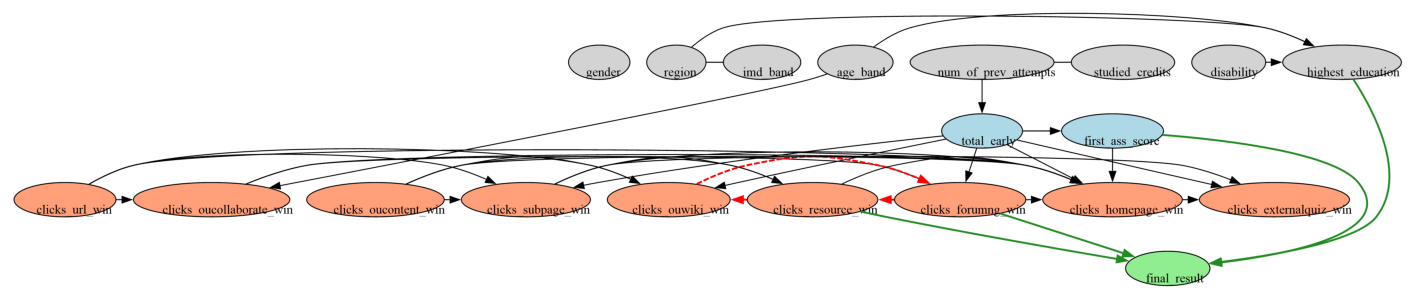

In [53]:
import io, pydot
import matplotlib.image as mpimg
import matplotlib.pyplot as plt
from causallearn.utils.GraphUtils import GraphUtils

dot_path = r"C:\Users\Disha Sharma\.conda\envs\analytics\Library\bin\dot.exe"   # full path: plain 'dot' fails here
pyd = GraphUtils.to_pydot(cg.G, labels=node_names)

def to_idx(x):
    # pydot may give a node reference as an int or as quoted text: turn both into a plain int
    return int(str(x).strip('"'))

tier_color = {0: 'lightgray', 1: 'lightblue', 2: 'lightsalmon', 3: 'lightgreen'}
for node in pyd.get_nodes():
    s = str(node.get_name()).strip('"')
    if not s.isdigit():
        continue                                     # skip pydot's default entries
    label = node_names[int(s)]
    node.set_style('filled'); node.set_fillcolor(tier_color[tier_of[label]])
    node.set_fontsize('10'); node.set_fixedsize('false'); node.set_margin('0.15,0.08')

for edge in pyd.get_edges():
    src = node_names[to_idx(edge.get_source())]
    dst = node_names[to_idx(edge.get_destination())]
    if 'final_result' in (src, dst):                 # edges touching the outcome in green
        edge.set_color('forestgreen'); edge.set_penwidth('2')
    if (src, dst) in cycle_edges:                    # the three cycle edges: red and dashed (left out of the DAG)
        edge.set_color('red'); edge.set_style('dashed'); edge.set_penwidth('2')

for t, names in tiers.items():                       # every variable of one tier on the same row
    sg = pydot.Subgraph(rank='same')
    for n in names:
        sg.add_node(pydot.Node(str(node_names.index(n))))
    pyd.add_subgraph(sg)

png_data = pyd.create_png(prog=dot_path)             # not pyd.write_png(): it calls plain 'dot'
with open(os.path.join(OUT_DIR, f"{MODULE}_checkpoint_PC_graph.png"), "wb") as f:
    f.write(png_data)
plt.figure(figsize=(18, 12))
plt.imshow(mpimg.imread(io.BytesIO(png_data)))
plt.axis('off')
plt.show()

### Stage 3.4 - Freeze the DAG: PC edges (cycle edges left out) + early-context edges (+ outcome edges after Stage 4.5); roles and adjustment sets

In [85]:
# Decisions from Stage 4.5 (empty on the first run, filled in later, then rerun this cell)
outcome_edge_acts = globals().get('outcome_edge_acts', [])
recourse_levers = globals().get('recourse_levers', [])

dag = nx.DiGraph()
dag.add_nodes_from(node_names)
dag.add_edges_from(directed_clean)               # PC edges without the three cycle edges (undirected pairs also left out)

# Addition 1: what a student did before the window can influence what they do in it
ctx_edges = [(src, c) for c in win_acts for src in ['total_early', 'first_ass_score'] if not dag.has_edge(src, c)]
dag.add_edges_from(ctx_edges)
# Addition 2: activities with a clear effect on the outcome when all others are held fixed (Stage 4.5)
outcome_edges = [(c, 'final_result') for c in outcome_edge_acts if not dag.has_edge(c, 'final_result')]
dag.add_edges_from(outcome_edges)
assert nx.is_directed_acyclic_graph(dag), "graph has a cycle"
print("edges from PC (kept):", len(directed_clean), "| context edges added:", len(ctx_edges), "| outcome edges added:", len(outcome_edges))

edges_out = pd.DataFrame([(a, b, 'PC') for a, b in directed_clean] +
                         [(a, b, 'PC, left out (cycle)') for a, b in cycle_edges] +
                         [(a, b, 'added: early context') for a, b in ctx_edges] +
                         [(a, b, 'added: direct effect (Stage 4.5)') for a, b in outcome_edges],
                         columns=['from', 'to', 'source'])
edges_out.to_csv(os.path.join(OUT_DIR, f"{MODULE}_checkpoint_dag_edges.csv"), index=False)

# Role of every variable, whether it reaches the outcome, and its adjustment set (= its direct parents)
role = {0: 'immutable context', 1: 'fixed context (known at checkpoint)', 2: 'action-window activity', 3: 'outcome'}
rows = []                                        # reset so reruns do not duplicate rows
for n in node_names:
    if n == 'final_result':
        continue
    rows.append({'variable': n, 'role': role[tier_of[n]],
                 'path_to_outcome': nx.has_path(dag, n, 'final_result'),
                 'direct_to_outcome': dag.has_edge(n, 'final_result'),
                 'adjustment_set': sorted(dag.predecessors(n))})
roles = pd.DataFrame(rows)
roles.to_csv(os.path.join(OUT_DIR, f"{MODULE}_checkpoint_roles_adjustment_sets.csv"), index=False)
levers = roles[(roles.role == 'action-window activity') & roles.path_to_outcome].variable.tolist()
print("treatments for effect estimation:", levers)
print("recourse levers:", recourse_levers)
print(roles[['variable', 'path_to_outcome', 'direct_to_outcome']].to_string(index=False))

edges from PC (kept): 32 | context edges added: 12 | outcome edges added: 6
treatments for effect estimation: ['clicks_externalquiz_win', 'clicks_forumng_win', 'clicks_homepage_win', 'clicks_oucollaborate_win', 'clicks_oucontent_win', 'clicks_ouwiki_win', 'clicks_resource_win', 'clicks_subpage_win', 'clicks_url_win']
recourse levers: ['clicks_oucontent_win', 'clicks_externalquiz_win', 'clicks_subpage_win', 'clicks_resource_win', 'clicks_oucollaborate_win', 'clicks_forumng_win', 'clicks_homepage_win']
                variable  path_to_outcome  direct_to_outcome
                  gender            False              False
                  region             True              False
       highest_education             True               True
                imd_band            False              False
                age_band             True              False
    num_of_prev_attempts             True              False
         studied_credits            False              False
      

### Stage 3.5 - Sensitivity: the same PC run with alpha 0.10 (no depth limit, it only takes seconds)

In [59]:
cg10 = pc(data, alpha=0.10, indep_test=gsq, background_knowledge=bk, node_names=node_names, show_progress=False)
d10_list, u10_list = read_edges(cg10)            # read_edges comes from Stage 3.2c
d10, u10 = set(d10_list), set(u10_list)

d05 = set(directed)
u05 = {tuple(sorted((a, b))) for a, b, _, _ in undirected}
print("edges at 0.05:", len(d05) + len(u05), "| at 0.10:", len(d10) + len(u10))
print("directed edges gained at 0.10:", sorted(d10 - d05))
print("directed edges lost at 0.10:", sorted(d05 - d10))
print("direct parents of final_result at 0.10:", sorted(a for a, b in d10 if b == 'final_result'))
print("cycles at 0.10:", list(nx.simple_cycles(nx.DiGraph(d10_list))))

edges at 0.05: 37 | at 0.10: 50
directed edges gained at 0.10: [('age_band', 'clicks_subpage_win'), ('clicks_externalquiz_win', 'clicks_homepage_win'), ('clicks_externalquiz_win', 'clicks_subpage_win'), ('clicks_homepage_win', 'final_result'), ('clicks_oucollaborate_win', 'clicks_url_win'), ('clicks_oucollaborate_win', 'final_result'), ('clicks_oucontent_win', 'clicks_forumng_win'), ('clicks_ouwiki_win', 'clicks_homepage_win'), ('clicks_ouwiki_win', 'clicks_oucontent_win'), ('clicks_ouwiki_win', 'clicks_subpage_win'), ('clicks_resource_win', 'clicks_url_win'), ('clicks_subpage_win', 'clicks_oucontent_win'), ('clicks_url_win', 'clicks_oucontent_win'), ('disability', 'region'), ('first_ass_score', 'clicks_oucontent_win'), ('gender', 'disability'), ('highest_education', 'disability'), ('imd_band', 'region'), ('studied_credits', 'final_result')]
directed edges lost at 0.10: [('clicks_homepage_win', 'clicks_externalquiz_win'), ('clicks_oucontent_win', 'clicks_ouwiki_win'), ('clicks_ouconten

### Stage 4.1 - Effect of each variable on final_result (DoWhy linear backdoor estimate, 95% interval, placebo and random-common-cause refutation)

In [87]:
import logging, warnings
from dowhy import CausalModel
warnings.filterwarnings('ignore')
logging.getLogger('dowhy').setLevel(logging.ERROR)

treatments = roles[roles.path_to_outcome].variable.tolist()      # every variable with a path to the outcome
print(len(treatments), "treatments:", treatments)

def estimate_one(t, adj):
    # One treatment at a time, adjusting only for its parents (the adjustment set)
    model = CausalModel(data=Gdf, treatment=t, outcome='final_result', common_causes=adj if adj else None)
    ident = model.identify_effect(proceed_when_unidentifiable=True)
    est = model.estimate_effect(ident, method_name="backdoor.linear_regression", confidence_intervals=True)
    ci = np.array(est.get_confidence_intervals(), dtype=float).flatten()
    out = {'ATE': float(est.value), 'CI_low': float(ci[0]), 'CI_high': float(ci[1])}
    try:   # refutation 1: a random fake treatment should have about zero effect
        r = model.refute_estimate(ident, est, method_name="placebo_treatment_refuter", placebo_type="permute", num_simulations=50)
        out['placebo_effect'] = float(r.new_effect)
        out['placebo_p'] = r.refutation_result.get('p_value') if isinstance(r.refutation_result, dict) else None
    except Exception as e:
        out['placebo_effect'], out['placebo_p'] = None, str(e)[:40]
    try:   # refutation 2: adding a random extra confounder should barely change the effect
        r = model.refute_estimate(ident, est, method_name="random_common_cause", num_simulations=50)
        out['random_cc_effect'] = float(r.new_effect)
    except Exception:
        out['random_cc_effect'] = None
    return out

results = []                         # reset before every rerun, otherwise reruns add duplicate rows
for t in treatments:
    adj = roles.loc[roles.variable == t, 'adjustment_set'].iloc[0]
    row = {'variable': t, 'role': roles.loc[roles.variable == t, 'role'].iloc[0],
           'adjustment_set': ', '.join(adj) if adj else '(none)'}
    row.update(estimate_one(t, adj))
    row['significant'] = (row['CI_low'] > 0) or (row['CI_high'] < 0)
    results.append(row)
    print("done:", t)
ate = pd.DataFrame(results)
cols = ['variable', 'role', 'ATE', 'CI_low', 'CI_high', 'significant', 'placebo_effect', 'placebo_p', 'random_cc_effect', 'adjustment_set']
print(ate[cols].round(3).to_string(index=False))
ate.to_csv(os.path.join(OUT_DIR, f"{MODULE}_checkpoint_ATE.csv"), index=False)

16 treatments: ['region', 'highest_education', 'age_band', 'num_of_prev_attempts', 'disability', 'total_early', 'first_ass_score', 'clicks_externalquiz_win', 'clicks_forumng_win', 'clicks_homepage_win', 'clicks_oucollaborate_win', 'clicks_oucontent_win', 'clicks_ouwiki_win', 'clicks_resource_win', 'clicks_subpage_win', 'clicks_url_win']
done: region
done: highest_education
done: age_band
done: num_of_prev_attempts
done: disability
done: total_early
done: first_ass_score
done: clicks_externalquiz_win
done: clicks_forumng_win
done: clicks_homepage_win
done: clicks_oucollaborate_win
done: clicks_oucontent_win
done: clicks_ouwiki_win
done: clicks_resource_win
done: clicks_subpage_win
done: clicks_url_win
                variable                                role    ATE  CI_low  CI_high  significant  placebo_effect  placebo_p  random_cc_effect                                                                                                                                            adjustme

### Stage 4.2 - Robustness: effects under heavier adjustment, and why the focus activity effect shrinks step by step

In [71]:
import statsmodels.api as sm

context = ['total_early', 'first_ass_score']                 # known before the window: safe to adjust for
background = ['gender', 'highest_education', 'imd_band', 'age_band', 'num_of_prev_attempts', 'studied_credits', 'disability']
reg_dummies = pd.get_dummies(Gdf['region'], prefix='reg', drop_first=True).astype(float)   # region is nominal: dummies

def ols_effect(t, adj, with_region=False):
    # Same linear model DoWhy uses: outcome ~ treatment + adjustment variables
    parts = [Gdf[[t] + adj].astype(float)]
    if with_region:
        parts.append(reg_dummies)
    X_ = sm.add_constant(pd.concat(parts, axis=1))
    m = sm.OLS(Gdf['final_result'].astype(float), X_).fit()
    lo, hi = m.conf_int().loc[t]
    return round(m.params[t], 3), round(lo, 3), round(hi, 3)

rows = []                                                    # reset before every rerun
for t in levers:
    graph_adj = roles.loc[roles.variable == t, 'adjustment_set'].iloc[0]
    plus_ctx = sorted(set(graph_adj) | set(context))
    plus_all = sorted(set(plus_ctx) | set(background))
    rows.append({'activity': t, 'graph_set': ols_effect(t, graph_adj),
                 '+context': ols_effect(t, plus_ctx), '+context+background': ols_effect(t, plus_all, with_region=True)})
print(pd.DataFrame(rows).to_string(index=False))

# Focus activity (externalquiz in DDD): description only, it has no path to the outcome in the graph
focus_win = f'clicks_{FOCUS_ACT}_win'
g_adj = roles.loc[roles.variable == focus_win, 'adjustment_set'].iloc[0]
steps = [('nothing', []), ('+ early clicks', ['total_early']), ('+ first assessment', context),
         ('+ graph set', sorted(set(g_adj) | set(context))), ('+ background', sorted(set(g_adj) | set(context) | set(background)))]
q = [{'adjusted for': l, 'effect (ATE, CI low, CI high)': ols_effect(focus_win, a, with_region=('background' in l))} for l, a in steps]
print("\nFocus activity effect, step by step:")
print(pd.DataFrame(q).to_string(index=False))

                activity             graph_set              +context   +context+background
      clicks_forumng_win (0.135, 0.104, 0.167) (0.135, 0.104, 0.167)  (0.13, 0.098, 0.161)
clicks_oucollaborate_win (0.074, 0.045, 0.102) (0.074, 0.045, 0.102)  (0.07, 0.042, 0.099)
    clicks_oucontent_win   (0.074, 0.048, 0.1)   (0.074, 0.048, 0.1) (0.069, 0.042, 0.095)
     clicks_resource_win  (0.06, 0.022, 0.099)  (0.06, 0.022, 0.099) (0.053, 0.015, 0.091)
      clicks_subpage_win  (0.076, 0.04, 0.112)  (0.076, 0.04, 0.112) (0.081, 0.045, 0.117)
          clicks_url_win (0.088, 0.063, 0.113) (0.088, 0.063, 0.113)  (0.085, 0.061, 0.11)

Focus activity effect, step by step:
      adjusted for effect (ATE, CI low, CI high)
           nothing         (0.288, 0.248, 0.327)
    + early clicks          (0.16, 0.118, 0.202)
+ first assessment           (0.12, 0.08, 0.159)
       + graph set           (0.059, 0.017, 0.1)
      + background         (0.067, 0.025, 0.108)


### Stage 4.3 - Where did the whole-course externalquiz effect go? Same simple model on three samples, then "any activity vs none"

In [80]:
base = feat.copy()                                           # all students, focus clicks up to day 56
base['y'] = base.final_result.map({'Withdrawn': 0, 'Fail': 1, 'Pass': 2, 'Distinction': 3})

def simple_effect(d, qcol, label):
    # Quartile-bin the focus clicks inside this sample, then regress the outcome on the bin number
    b = pd.qcut(d[qcol], q=4, labels=False, duplicates='drop').astype(float).rename('bin')
    m = sm.OLS(d['y'].astype(float), sm.add_constant(b)).fit()
    lo, hi = m.conf_int().loc['bin']
    return {'sample': label, 'n': len(d), 'bins': int(b.nunique()),     # bins = how many bins the split really gave
            'effect_per_bin': round(m.params['bin'], 3), 'CI': (round(lo, 3), round(hi, 3))}

rows = [simple_effect(base, 'focus_clicks_d56', 'all students, clicks up to day 56'),
        simple_effect(base[base.enrolled_d56], 'focus_clicks_d56', 'enrolled at day 56, clicks up to day 56')]
win_df = pd.DataFrame({'y': G.final_result, 'q': X.loc[G.index, focus_win]})
rows.append(simple_effect(win_df, 'q', 'enrolled at day 56, window clicks only'))
print(pd.DataFrame(rows).to_string(index=False))

any_focus = (X.loc[G.index, focus_win] > 0).astype(float).rename('any_focus')
adj_focus = sorted(set(g_adj) | set(context))
Xd = sm.add_constant(pd.concat([any_focus, Gdf[adj_focus].astype(float)], axis=1))
mm = sm.OLS(Gdf['final_result'].astype(float), Xd).fit()
lo, hi = mm.conf_int().loc['any_focus']
print("share with any externalquiz clicks in the window:", round(any_focus.mean() * 100, 1), "%")
print("effect of any vs none:", round(mm.params['any_focus'], 3), (round(lo, 3), round(hi, 3)))

                                 sample    n  bins  effect_per_bin             CI
      all students, clicks up to day 56 4969     3           0.396 (0.365, 0.426)
enrolled at day 56, clicks up to day 56 3962     4           0.172 (0.148, 0.196)
 enrolled at day 56, window clicks only 3962     2           0.438  (0.37, 0.506)
share with any externalquiz clicks in the window: 38.6 %
effect of any vs none: 0.102 (0.043, 0.16)


### Stage 4.4 - Each activity level versus no activity (adjusted for early clicks and first assessment only)

In [73]:
context_vars = ['total_early', 'first_ass_score']

def level_effects(t):
    # Effect of level 1, 2, 3 versus level 0 (no activity)
    d = pd.get_dummies(Gdf[t].astype(int), prefix='lvl').astype(float).drop(columns='lvl_0')
    X_ = sm.add_constant(pd.concat([d, Gdf[context_vars].astype(float)], axis=1))
    m = sm.OLS(Gdf['final_result'].astype(float), X_).fit()
    out = {'activity': short(t), '% with none': round((Gdf[t] == 0).mean() * 100, 1)}
    for lv in ['lvl_1', 'lvl_2', 'lvl_3']:
        if lv in m.params.index:
            lo, hi = m.conf_int().loc[lv]
            out[lv.replace('lvl_', 'level ') + ' vs none'] = f"{m.params[lv]:.3f} ({lo:.3f}, {hi:.3f})"
        else:
            out[lv.replace('lvl_', 'level ') + ' vs none'] = 'n/a'     # externalquiz has only 3 levels in DDD
    return out

print("Effect on final_result (0-3) versus no activity; level 1 = lowest third of active students")
print(pd.DataFrame([level_effects(t) for t in win_acts]).to_string(index=False))

Effect on final_result (0-3) versus no activity; level 1 = lowest third of active students
     activity  % with none        level 1 vs none       level 2 vs none       level 3 vs none
 externalquiz         61.4   0.177 (0.116, 0.237)  0.198 (0.112, 0.284)                   n/a
      forumng         23.0   0.181 (0.105, 0.256)  0.293 (0.210, 0.377)  0.470 (0.373, 0.566)
     homepage          7.0 -0.014 (-0.122, 0.094)  0.266 (0.150, 0.381)  0.373 (0.245, 0.500)
oucollaborate         70.9   0.188 (0.116, 0.261) 0.069 (-0.057, 0.194)  0.281 (0.191, 0.371)
    oucontent         11.6   0.248 (0.158, 0.339)  0.271 (0.178, 0.364)  0.322 (0.227, 0.416)
       ouwiki         55.3   0.123 (0.048, 0.198)  0.123 (0.050, 0.196) 0.044 (-0.032, 0.120)
     resource         15.2   0.206 (0.123, 0.288)  0.370 (0.282, 0.457)  0.372 (0.281, 0.462)
      subpage         13.9   0.221 (0.136, 0.306)  0.321 (0.233, 0.409)  0.402 (0.307, 0.497)
          url         34.2   0.127 (0.060, 0.195)  0.221 (0.147

### Stage 4.5 - All activities together, split into participation (any vs none) and volume (each extra level)

In [77]:
parts = {}
for t in win_acts:
    lvl = Gdf[t].astype(int)
    parts[short(t) + '_any'] = (lvl > 0).astype(float)               # participation: any activity vs none
    parts[short(t) + '_more'] = (lvl - 1).clip(lower=0).astype(float)  # volume: levels above the first

Xj2 = sm.add_constant(pd.concat([pd.DataFrame(parts), Gdf[context_vars].astype(float)], axis=1))
mj2 = sm.OLS(Gdf['final_result'].astype(float), Xj2).fit()            # one regression, all activities together
ci = mj2.conf_int()
res = pd.DataFrame({'effect': mj2.params, 'lo': ci[0], 'hi': ci[1]})
rows = []                                                             # reset before every rerun
for t in win_acts:
    r = {'activity': short(t)}
    for kind, label in [('_any', 'participation (any vs none)'), ('_more', 'volume (per extra level)')]:
        e = res.loc[short(t) + kind]
        r[label] = f"{e.effect:.3f} ({e.lo:.3f}, {e.hi:.3f})"
    rows.append(r)
print(pd.DataFrame(rows).to_string(index=False))
print("R-squared:", round(mj2.rsquared, 3))
res.round(3).to_csv(os.path.join(OUT_DIR, f"{MODULE}_checkpoint_participation_volume_effects.csv"))

     activity participation (any vs none) volume (per extra level)
 externalquiz        0.092 (0.030, 0.154)   -0.023 (-0.112, 0.066)
      forumng        0.088 (0.006, 0.171)     0.089 (0.043, 0.135)
     homepage     -0.454 (-0.613, -0.295)     0.065 (0.011, 0.118)
oucollaborate        0.075 (0.004, 0.147)    0.028 (-0.023, 0.079)
    oucontent        0.207 (0.064, 0.350)   -0.004 (-0.040, 0.031)
       ouwiki        0.112 (0.040, 0.184)  -0.085 (-0.132, -0.039)
     resource        0.120 (0.002, 0.237)    0.026 (-0.016, 0.069)
      subpage        0.130 (0.009, 0.251)   -0.009 (-0.056, 0.038)
          url       0.023 (-0.049, 0.095)    0.013 (-0.030, 0.056)
R-squared: 0.247


### Stage 4.5b - Corrected participation versus volume table (homepage as levels), with intervals and the strict lever rule applied

In [105]:
ci_b = mb.conf_int()                                   # mb = Stage 5.2d rerun with homepage entered as levels
rows = []                                              # reset before every rerun
for t in win_acts:
    r = {'activity': short(t)}
    if t == 'clicks_homepage_win':                     # homepage: levels only, no 'any' term
        k = 'homepage_level'
        r.update({'any': np.nan, 'any_lo': np.nan, 'any_hi': np.nan,
                  'more': mb.params[k], 'more_lo': ci_b.loc[k, 0], 'more_hi': ci_b.loc[k, 1]})
    else:
        ka, km = short(t) + '_any', short(t) + '_more'
        r.update({'any': mb.params[ka], 'any_lo': ci_b.loc[ka, 0], 'any_hi': ci_b.loc[ka, 1],
                  'more': mb.params[km], 'more_lo': ci_b.loc[km, 0], 'more_hi': ci_b.loc[km, 1]})
    # Strict rule: volume lever if the per-level interval is above 0;
    # start lever if 'any' is above 0 and the per-level interval includes 0; otherwise not a lever
    if r['more_lo'] > 0:
        r['type'] = 'volume lever'
    elif r['any_lo'] > 0 and r['more_hi'] >= 0:
        r['type'] = 'start lever'
    elif r['any_lo'] > 0 or r['more_hi'] < 0:
        r['type'] = 'clear effect, not a lever'
    else:
        r['type'] = 'no clear effect'
    rows.append(r)
tab = pd.DataFrame(rows)
print(tab.round(3).to_string(index=False))
print("R-squared:", round(mb.rsquared, 3))

# Compare the levers with the causal-model coefficients (coefs comes from Stage 5.2c)
for _, r in tab.iterrows():
    n = f"clicks_{r['activity']}_win"
    if r['type'] in ('start lever', 'volume lever'):
        ref = r['any'] if r['type'] == 'start lever' else r['more']
        print(f"{r['activity']:<14} {r['type']:<13} corrected 4.5: {ref:.3f} | model: {coefs[n]:.3f} | gap: {abs(coefs[n] - ref):.3f}")
print("\nProposed part_nodes:", [f"clicks_{a}_win" for a in tab[tab.type == 'start lever'].activity])
print("Proposed vol_nodes:", [f"clicks_{a}_win" for a in tab[tab.type == 'volume lever'].activity])

     activity   any  any_lo  any_hi   more  more_lo  more_hi                      type
 externalquiz 0.102   0.040   0.164 -0.020   -0.109    0.069               start lever
      forumng 0.055  -0.028   0.137  0.110    0.065    0.156              volume lever
     homepage   NaN     NaN     NaN  0.021   -0.031    0.073           no clear effect
oucollaborate 0.080   0.008   0.152  0.028   -0.024    0.079               start lever
    oucontent 0.022  -0.109   0.152  0.004   -0.031    0.039           no clear effect
       ouwiki 0.109   0.036   0.181 -0.081   -0.128   -0.034 clear effect, not a lever
     resource 0.096  -0.021   0.214  0.034   -0.009    0.076           no clear effect
      subpage 0.046  -0.072   0.165  0.000   -0.047    0.047           no clear effect
          url 0.029  -0.043   0.101  0.021   -0.023    0.064           no clear effect
R-squared: 0.24
externalquiz   start lever   corrected 4.5: 0.102 | model: 0.107 | gap: 0.005
forumng        volume lever  correct

### Stage 5.0 - Record the decisions (Option B: all 7 levers), then rerun Stage 3.4 and Stage 4.1

In [83]:
# Decisions for DDD (Option B: strict rule, 7 levers)
part_nodes = ['clicks_oucontent_win', 'clicks_externalquiz_win', 'clicks_subpage_win',
              'clicks_resource_win', 'clicks_oucollaborate_win']           # start-type levers (coded 0/1 in the model)
vol_nodes = ['clicks_forumng_win', 'clicks_homepage_win']                  # volume-type levers (raise by one level)
outcome_edge_acts = ['clicks_externalquiz_win', 'clicks_homepage_win', 'clicks_oucollaborate_win',
                     'clicks_oucontent_win', 'clicks_ouwiki_win', 'clicks_subpage_win']   # direct edges to add (PC did not link them)
recourse_levers = part_nodes + vol_nodes
# Now rerun Stage 3.4 (it reads outcome_edge_acts and recourse_levers), then Stage 4.1.

### Stage 5.0 (revised) - Record the lever decisions from the corrected Stage 4.5b table

In [108]:
# Decisions for DDD after the correction: strict rule applied to the corrected table (Stage 4.5b)
part_nodes = ['clicks_externalquiz_win', 'clicks_oucollaborate_win']   # start-type levers (coded 0/1 in the model)
vol_nodes = ['clicks_forumng_win']                                     # volume-type lever (raise by one level)
# outcome_edge_acts is NOT changed: the six edges added earlier stay in the graph (documented as a deviation)
recourse_levers = part_nodes + vol_nodes
print("start levers:", [short(n) for n in part_nodes], "| volume levers:", [short(n) for n in vol_nodes])

start levers: ['externalquiz', 'oucollaborate'] | volume levers: ['forumng']


### Stage 5.1 - Fit the invertible causal model on the frozen DAG and check it (fit, invertibility, graph structure)

nodes: 17 | edges: 50
region | EmpiricalDistribution | NoneType
highest_education | DiscreteAdditiveNoiseModel | SklearnRegressionModel
age_band | EmpiricalDistribution | NoneType
num_of_prev_attempts | EmpiricalDistribution | NoneType
disability | EmpiricalDistribution | NoneType
total_early | DiscreteAdditiveNoiseModel | SklearnRegressionModel
first_ass_score | DiscreteAdditiveNoiseModel | SklearnRegressionModel
clicks_externalquiz_win | DiscreteAdditiveNoiseModel | SklearnRegressionModel
clicks_forumng_win | DiscreteAdditiveNoiseModel | SklearnRegressionModel
clicks_homepage_win | DiscreteAdditiveNoiseModel | SklearnRegressionModel
clicks_oucollaborate_win | DiscreteAdditiveNoiseModel | SklearnRegressionModel
clicks_oucontent_win | DiscreteAdditiveNoiseModel | SklearnRegressionModel
clicks_ouwiki_win | DiscreteAdditiveNoiseModel | SklearnRegressionModel
clicks_resource_win | DiscreteAdditiveNoiseModel | SklearnRegressionModel
clicks_subpage_win | DiscreteAdditiveNoiseModel | Sklearn

Test permutations of given graph: 100%|██████████| 50/50 [13:36<00:00, 16.32s/it]


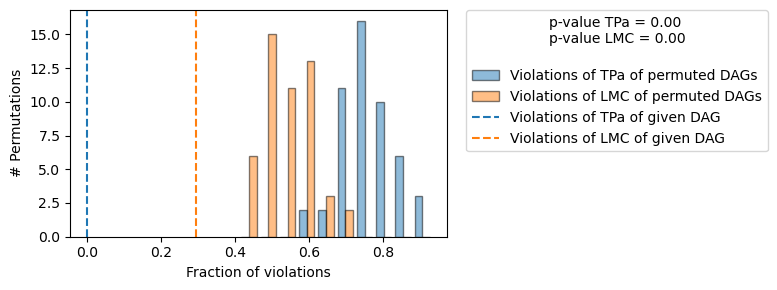

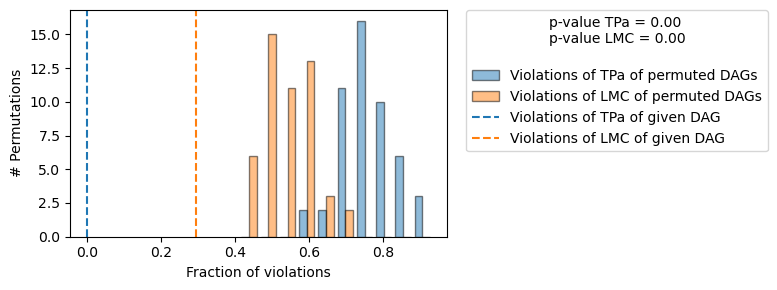

Evaluated the performance of the causal mechanisms and the invertibility assumption of the causal mechanisms and the overall average KL divergence between generated and observed distribution and the graph structure. The results are as follows:
- R2 coefficient: Indicates how much variance is explained by the conditional expectations of the mechanisms. Note, however, that this can be misleading for nonlinear relationships.
--- Node region
--- Node age_band
--- Node num_of_prev_attempts
--- Node disability
--- Node total_early
- The R2 coefficient is -0.05175561588931608.
--- Node highest_education
- The R2 coefficient is -0.051360154604065.
--- Node first_ass_score
- The R2 coefficient is 0.11444493351784316.
--- Node clicks_oucontent_win
- The R2 coefficient is 0.08916809933006124.
--- Node clicks_url_win
- The R2 coefficient is 0.1305648288157086.
--- Node clicks_oucollaborate_win
- The R2 coefficient is 0.0827935334934301.
--- Node clicks_ouwiki_win
- The R2 coefficient is 0.05755707

In [90]:
import dowhy.gcm as gcm
import pickle
try:
    from dowhy.graph import get_ordered_predecessors          # path in this DoWhy version
except ImportError:
    get_ordered_predecessors = lambda g, n: sorted(g.predecessors(n))

# Model variables = variables with a path to the outcome, plus the outcome
scm_cols = roles[roles.path_to_outcome].variable.tolist() + ['final_result']
dag_scm = dag.subgraph(scm_cols).copy()
df_scm = Gdf[scm_cols].astype(float)                           # gcm wants numeric data
print("nodes:", dag_scm.number_of_nodes(), "| edges:", dag_scm.number_of_edges())

scm = gcm.InvertibleStructuralCausalModel(dag_scm.copy())      # invertible: each student keeps their own noise
gcm.auto.assign_causal_mechanisms(scm, df_scm)
for n in dag_scm.nodes:
    mech = scm.causal_mechanism(n)
    print(n, "|", type(mech).__name__, "|", type(getattr(mech, "prediction_model", None)).__name__)

gcm.fit(scm, df_scm)
ev = gcm.evaluate_causal_model(scm, df_scm, compare_mechanism_baselines=True)   # slow: keep the laptop awake
with open(os.path.join(OUT_DIR, f"{MODULE}_checkpoint_scm.pkl"), "wb") as f:
    pickle.dump(scm, f)
with open(os.path.join(OUT_DIR, f"{MODULE}_checkpoint_scm_evaluation.txt"), "w") as f:
    f.write(str(ev))
for line in str(ev).splitlines():
    if any(k in line for k in ["--- Node", "R2 coefficient", "model assumption", "violates", "overall average KL"]):
        print(line)

### Stage 5.2a - Helpers: read the evaluation report, and build a model on its OWN copy of the graph

In [95]:
import re

def to_num(s):
    # Report sentences end with a full stop right after the number
    return float(s.rstrip('.'))

def parse_eval(text):
    # Pull R-squared and the invertibility result per node out of the report text
    r2, inv, cur = {}, {}, None
    for line in text.splitlines():
        m = re.match(r'--- Node (\S+)', line)
        if m:
            cur = m.group(1)
            continue
        m = re.search(r'The R2 coefficient is ([\-0-9.eE+]+)', line)
        if m and cur:
            r2[cur] = to_num(m.group(1))
        m = re.search(r'assumption for node (\S+) is (not rejected|rejected) with a p-value of ([0-9.eE+\-]+)', line)
        if m:
            inv[m.group(1)] = (m.group(2), to_num(m.group(3)))
    return r2, inv

def build_scm(variant, data, graph):
    # IMPORTANT: every model gets its OWN copy of the graph. Models built on one shared graph overwrite each other.
    s = gcm.InvertibleStructuralCausalModel(graph.copy())
    gcm.auto.assign_causal_mechanisms(s, data)                # roots keep their empirical distributions
    if variant == 'auto':
        return s
    for n in graph.nodes:
        if graph.in_degree(n) == 0:
            continue
        reg = gcm.ml.create_linear_regressor() if variant == 'linear' else gcm.ml.create_hist_gradient_boost_regressor()
        s.set_causal_mechanism(n, gcm.AdditiveNoiseModel(reg))
    return s

def comparison_table(reports, graph):
    # One row per non-root node, one R-squared and invertibility column pair per model
    rows = []
    for n in [x for x in graph.nodes if graph.in_degree(x) > 0]:
        row = {'node': n}
        for v, (r2, inv) in reports.items():
            row[v + ' R2'] = round(r2.get(n, np.nan), 3)
            row[v + ' invertible'] = f"{'no' if inv.get(n, ('', 0))[0] == 'rejected' else 'yes'} (p={inv.get(n, ('', np.nan))[1]:.3g})"
        rows.append(row)
    return pd.DataFrame(rows)

### Stage 5.2b - Compare mechanism types on the level-coded data: automatic, linear, boosted (fit and invertibility per node)

In [97]:
reports = {}                                       # reset so reruns do not mix old results
for v in ['auto', 'linear', 'boosted']:
    s = build_scm(v, df_scm, dag_scm)
    gcm.fit(s, df_scm)
    # skip the slow structure test and KL here: only per-node fit and invertibility are needed
    ev_v = gcm.evaluate_causal_model(s, df_scm, compare_mechanism_baselines=False,
                                     evaluate_causal_structure=False, evaluate_overall_kl_divergence=False)
    reports[v] = parse_eval(str(ev_v))
    with open(os.path.join(OUT_DIR, f"{MODULE}_checkpoint_scm_{v}_levels.pkl"), "wb") as f:
        pickle.dump(s, f)
comp = comparison_table(reports, dag_scm)
print(comp.to_string(index=False))
comp.to_csv(os.path.join(OUT_DIR, f"{MODULE}_checkpoint_scm_mechanism_comparison.csv"), index=False)

Evaluating causal mechanisms...: 100%|██████████| 17/17 [00:00<00:00, 4325.07it/s]


                    node  auto R2 auto invertible  linear R2 linear invertible  boosted R2 boosted invertible
       highest_education   -0.042 no (p=5.05e-14)      0.031   no (p=1.22e-11)       0.060    no (p=1.69e-11)
             total_early   -0.052 no (p=2.54e-05)      0.046   no (p=0.000643)       0.046     no (p=0.00788)
         first_ass_score    0.115 no (p=1.06e-10)      0.140   no (p=4.74e-08)       0.146    no (p=3.69e-08)
 clicks_externalquiz_win    0.115        no (p=0)      0.261          no (p=0)       0.268           no (p=0)
      clicks_forumng_win    0.429 no (p=2.13e-09)      0.497          no (p=0)       0.505           no (p=0)
     clicks_homepage_win    0.674        no (p=0)      0.733          no (p=0)       0.733           no (p=0)
clicks_oucollaborate_win    0.084        no (p=0)      0.173          no (p=0)       0.148           no (p=0)
    clicks_oucontent_win    0.084 no (p=0.000353)      0.098   no (p=9.86e-08)       0.129     no (p=0.00135)
       cli

### Stage 5.2c - Rebuild the models with participation coding (0/1) for the five start-type activities, each on its own graph copy, and check the lever coefficients

In [99]:
# Start-type activities (Stage 5.0) become 0 = none, 1 = any: levels would hide the start effect
df_scm2 = df_scm.copy()
for c in part_nodes:
    df_scm2[c] = (df_scm2[c] > 0).astype(float)

scms2, reports2 = {}, {}                           # reset so reruns do not mix old results
for v in ['linear', 'boosted']:
    s = build_scm(v, df_scm2, dag_scm)             # each model on its own copy of the graph
    gcm.fit(s, df_scm2)
    ev_v = gcm.evaluate_causal_model(s, df_scm2, compare_mechanism_baselines=False,
                                     evaluate_causal_structure=False, evaluate_overall_kl_divergence=False)
    scms2[v] = s
    reports2[v] = parse_eval(str(ev_v))
    with open(os.path.join(OUT_DIR, f"{MODULE}_checkpoint_scm_{v}_participation.pkl"), "wb") as f:
        pickle.dump(s, f)

# The outcome mechanism of the linear model: effect per parent (start-type parents are now 'start vs none')
lin2 = scms2['linear'].causal_mechanism('final_result').prediction_model.sklearn_model
par2 = get_ordered_predecessors(scms2['linear'].graph, 'final_result')
coefs = pd.Series(lin2.coef_.ravel(), index=par2)
print("linear outcome mechanism (participation coding):")
print(coefs.round(3).to_string())

# Compare each lever with its Stage 4.5 effect (res comes from that cell): start-type with 'any vs none', volume-type with 'per level'
cmp_rows = []                                      # reset before every rerun
for n in part_nodes:
    cmp_rows.append({'lever': short(n), 'type': 'start', 'model coefficient': coefs[n],
                     'Stage 4.5 effect': res.loc[short(n) + '_any', 'effect']})
for n in vol_nodes:
    cmp_rows.append({'lever': short(n), 'type': 'volume', 'model coefficient': coefs[n],
                     'Stage 4.5 effect': res.loc[short(n) + '_more', 'effect']})
cmp = pd.DataFrame(cmp_rows)
cmp['difference'] = (cmp['model coefficient'] - cmp['Stage 4.5 effect']).abs()
print("\nLever coefficients versus Stage 4.5 (target: difference within about 0.05):")
print(cmp.round(3).to_string(index=False))
print("\noutcome R-squared:", {v: round(reports2[v][0]['final_result'], 3) for v in reports2})
print("\n", comparison_table(reports2, dag_scm).to_string(index=False))

Evaluating causal mechanisms...: 100%|██████████| 17/17 [00:00<00:00, 3650.21it/s]


linear outcome mechanism (participation coding):
clicks_externalquiz_win     0.107
clicks_forumng_win          0.095
clicks_homepage_win         0.048
clicks_oucollaborate_win    0.105
clicks_oucontent_win        0.014
clicks_ouwiki_win          -0.011
clicks_resource_win         0.115
clicks_subpage_win          0.050
first_ass_score             0.281
highest_education           0.092

Lever coefficients versus Stage 4.5 (target: difference within about 0.05):
        lever   type  model coefficient  Stage 4.5 effect  difference
    oucontent  start              0.014             0.207       0.193
 externalquiz  start              0.107             0.092       0.015
      subpage  start              0.050             0.130       0.080
     resource  start              0.115             0.120       0.005
oucollaborate  start              0.105             0.075       0.030
      forumng volume              0.095             0.089       0.006
     homepage volume              0.048     

### Stage 5.2c (revised) - Rebuild the models with participation coding (0/1) for the two start-type levers, each on its own graph copy, and check the lever coefficients

In [111]:
# Start-type levers (Stage 5.0) become 0 = none, 1 = any: levels would hide the start effect
df_scm2 = df_scm.copy()
for c in part_nodes:
    df_scm2[c] = (df_scm2[c] > 0).astype(float)

scms2, reports2 = {}, {}                           # reset so reruns do not mix old results
for v in ['linear', 'boosted']:
    s = build_scm(v, df_scm2, dag_scm)             # each model on its own copy of the graph
    gcm.fit(s, df_scm2)
    ev_v = gcm.evaluate_causal_model(s, df_scm2, compare_mechanism_baselines=False,
                                     evaluate_causal_structure=False, evaluate_overall_kl_divergence=False)
    scms2[v] = s
    reports2[v] = parse_eval(str(ev_v))
    with open(os.path.join(OUT_DIR, f"{MODULE}_checkpoint_scm_{v}_participation.pkl"), "wb") as f:
        pickle.dump(s, f)

# The outcome mechanism of the linear model: effect per parent (start-type parents are now 'start vs none')
lin2 = scms2['linear'].causal_mechanism('final_result').prediction_model.sklearn_model
par2 = get_ordered_predecessors(scms2['linear'].graph, 'final_result')
coefs = pd.Series(lin2.coef_.ravel(), index=par2)
print("linear outcome mechanism (participation coding):")
print(coefs.round(3).to_string())

# Compare each lever with the CORRECTED Stage 4.5b table (tab): start-type with 'any vs none', volume-type with 'per level'
cmp_rows = []                                      # reset before every rerun
for n in part_nodes:
    r = tab[tab.activity == short(n)].iloc[0]
    cmp_rows.append({'lever': short(n), 'type': 'start', 'model coefficient': coefs[n], 'corrected 4.5b': r['any']})
for n in vol_nodes:
    r = tab[tab.activity == short(n)].iloc[0]
    cmp_rows.append({'lever': short(n), 'type': 'volume', 'model coefficient': coefs[n], 'corrected 4.5b': r['more']})
cmp = pd.DataFrame(cmp_rows)
cmp['difference'] = (cmp['model coefficient'] - cmp['corrected 4.5b']).abs()
print("\nLever coefficients versus corrected Stage 4.5b (target: difference within about 0.05):")
print(cmp.round(3).to_string(index=False))
print("\noutcome R-squared:", {v: round(reports2[v][0]['final_result'], 3) for v in reports2})
print("\n", comparison_table(reports2, dag_scm).to_string(index=False))

Evaluating causal mechanisms...: 100%|██████████| 17/17 [00:00<00:00, 4100.00it/s]


linear outcome mechanism (participation coding):
clicks_externalquiz_win     0.098
clicks_forumng_win          0.096
clicks_homepage_win         0.031
clicks_oucollaborate_win    0.100
clicks_oucontent_win        0.018
clicks_ouwiki_win          -0.017
clicks_resource_win         0.041
clicks_subpage_win          0.023
first_ass_score             0.286
highest_education           0.092

Lever coefficients versus corrected Stage 4.5b (target: difference within about 0.05):
        lever   type  model coefficient  corrected 4.5b  difference
 externalquiz  start              0.098           0.102       0.004
oucollaborate  start              0.100           0.080       0.020
      forumng volume              0.096           0.110       0.015

outcome R-squared: {'linear': 0.236, 'boosted': 0.199}

                     node  linear R2 linear invertible  boosted R2 boosted invertible
       highest_education      0.033   no (p=7.34e-12)       0.057    no (p=8.35e-10)
             total_earl

### Stage 5.2d - Why do two lever coefficients differ from Stage 4.5? Overlap check and a rerun of 4.5 without the homepage start term

In [102]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Part 1: how much do the Stage 4.5 start terms overlap? (VIF above about 5 = strongly overlapping)
vif = pd.Series({c: variance_inflation_factor(Xj2.values, i)
                 for i, c in enumerate(Xj2.columns) if c != 'const'})
print("VIF of the Stage 4.5 start terms:")
print(vif[[c for c in vif.index if c.endswith('_any')]].round(1).to_string())

# Part 2: rerun 4.5 with homepage entered as levels only (no 'any' term), without and with education
parts_b = {}                                                      # reset before every rerun
for t in win_acts:
    lvl = Gdf[t].astype(int)
    if t == 'clicks_homepage_win':
        parts_b['homepage_level'] = lvl.astype(float)             # homepage as levels
        continue
    parts_b[short(t) + '_any'] = (lvl > 0).astype(float)
    parts_b[short(t) + '_more'] = (lvl - 1).clip(lower=0).astype(float)
Xb = sm.add_constant(pd.concat([pd.DataFrame(parts_b), Gdf[context_vars].astype(float)], axis=1))
mb = sm.OLS(Gdf['final_result'].astype(float), Xb).fit()
Xc = sm.add_constant(pd.concat([pd.DataFrame(parts_b), Gdf[context_vars + ['highest_education']].astype(float)], axis=1))
mc = sm.OLS(Gdf['final_result'].astype(float), Xc).fit()          # same, plus education (the model adjusts for it)

rows = []                                                         # reset before every rerun
for n in part_nodes:                                              # start-type levers: the 'any' term
    k = short(n) + '_any'
    rows.append({'lever': short(n) + ' (start)', 'Stage 4.5': res.loc[k, 'effect'],
                 'homepage as levels': mb.params[k], '+ education': mc.params[k], 'model': coefs[n]})
rows.append({'lever': 'forumng (per level)', 'Stage 4.5': res.loc['forumng_more', 'effect'],
             'homepage as levels': mb.params['forumng_more'], '+ education': mc.params['forumng_more'],
             'model': coefs['clicks_forumng_win']})
rows.append({'lever': 'homepage (per level)', 'Stage 4.5': res.loc['homepage_more', 'effect'],
             'homepage as levels': mb.params['homepage_level'], '+ education': mc.params['homepage_level'],
             'model': coefs['clicks_homepage_win']})
print("\nLever effects: Stage 4.5 versus the reruns versus the causal model:")
print(pd.DataFrame(rows).round(3).to_string(index=False))
print("R-squared of the reruns:", round(mb.rsquared, 3), "and", round(mc.rsquared, 3))

VIF of the Stage 4.5 start terms:
externalquiz_any     1.5
forumng_any          2.0
homepage_any         2.8
oucollaborate_any    1.8
oucontent_any        3.5
ouwiki_any           2.1
resource_any         3.0
subpage_any          2.9
url_any              1.9

Lever effects: Stage 4.5 versus the reruns versus the causal model:
                lever  Stage 4.5  homepage as levels  + education  model
    oucontent (start)      0.207               0.022        0.024  0.014
 externalquiz (start)      0.092               0.102        0.103  0.107
      subpage (start)      0.130               0.046        0.043  0.050
     resource (start)      0.120               0.096        0.095  0.115
oucollaborate (start)      0.075               0.080        0.080  0.105
  forumng (per level)      0.089               0.110        0.106  0.095
 homepage (per level)      0.065               0.021        0.024  0.048
R-squared of the reruns: 0.24 and 0.245


### Stage 5.3 - What-if shifts: start externalquiz, start oucollaborate, raise forum one level, and bundles (Fail and late leavers)

In [114]:
cohort_lab = G.loc[df_scm2.index, 'cohort']              # 'fail', 'late_leaver' or 'success' per row

def raise_to(nodes, level=1):
    # Raise-only: students already at or above the level are left unchanged
    return {n: (lambda x, l=level: np.maximum(x, l)) for n in nodes}

def step_up(nodes):
    # One level more, capped at level 3
    return {n: (lambda x: np.minimum(x + 1, 3)) for n in nodes}

# The actions we may recommend (from Stage 5.0)
actions = {short(n): raise_to([n]) for n in part_nodes}           # start-type: externalquiz, oucollaborate
actions.update({short(n) + '_up': step_up([n]) for n in vol_nodes})   # volume-type: forumng_up

def merge_actions(names):
    # Combine several actions into one set of interventions
    iv = {}
    for a in names:
        iv.update(actions[a])
    return iv

scenarios = {a: actions[a] for a in actions}                      # each action alone
scenarios['all starts'] = merge_actions([short(n) for n in part_nodes])
scenarios['all actions'] = merge_actions(list(actions))

rows = []                                                         # reset before every rerun
for model_name, model in scms2.items():
    for cname in ['fail', 'late_leaver']:
        d = df_scm2[cohort_lab == cname].reset_index(drop=True)
        for sname, iv in scenarios.items():
            cf = gcm.counterfactual_samples(model, iv, observed_data=d)      # student-level what-if (approximate)
            shift = cf['final_result'].values - d['final_result'].values
            elig = np.zeros(len(d), dtype=bool)                              # students the action actually changes
            for n, fn in iv.items():
                elig |= (np.asarray(fn(d[n].values)) != d[n].values)
            rows.append({'model': model_name, 'cohort': cname, 'scenario': sname, 'n': len(d),
                         '% affected': round(elig.mean() * 100, 1),
                         'mean shift (all)': round(shift.mean(), 3),
                         'mean shift (affected)': round(shift[elig].mean(), 3) if elig.any() else np.nan})
res2 = pd.DataFrame(rows)
res2.to_csv(os.path.join(OUT_DIR, f"{MODULE}_checkpoint_whatif_shifts_participation.csv"), index=False)
print(res2[res2.model == 'linear'].drop(columns='model').to_string(index=False))
print("\nMean shift among affected students, linear vs boosted:")
print(res2.pivot_table(index=['cohort', 'scenario'], columns='model', values='mean shift (affected)').round(3).to_string())

     cohort      scenario    n  % affected  mean shift (all)  mean shift (affected)
       fail  externalquiz 1048        75.9             0.074                  0.098
       fail oucollaborate 1048        84.4             0.129                  0.153
       fail    forumng_up 1048        89.9             0.096                  0.107
       fail    all starts 1048        92.6             0.202                  0.218
       fail   all actions 1048        97.2             0.286                  0.294
late_leaver  externalquiz  816        71.3             0.070                  0.098
late_leaver oucollaborate  816        79.0             0.121                  0.153
late_leaver    forumng_up  816        84.7             0.091                  0.107
late_leaver    all starts  816        89.3             0.189                  0.212
late_leaver   all actions  816        95.2             0.267                  0.280

Mean shift among affected students, linear vs boosted:
model               

### Stage 5.4 - Chance of reaching the target: one noise pool, with the cut-off calibrated to the real share

In [117]:
def outcome_mean(model, data):
    # Predicted outcome without noise. .ravel() because the linear model returns a column, the boosted one a flat list
    mech = model.causal_mechanism('final_result')
    par = get_ordered_predecessors(model.graph, 'final_result')
    return np.asarray(mech.prediction_model.predict(data[par].to_numpy())).ravel()

def prob_reach(f_vals, resid, T):
    # For each student: share of leftover errors (whole enrolled sample) for which prediction + error reaches T
    # Sorted lookup, so no big table is needed
    assert f_vals.ndim == 1 and resid.ndim == 1, "predictions and residuals must both be flat"
    rs = np.sort(resid)
    return (len(rs) - np.searchsorted(rs, T - f_vals, side='left')) / len(rs)

def calibrated_T(f_all, resid, real_share):
    # Find the cut-off at which the average chance over all enrolled students equals the real share
    lo, hi = -2.0, 5.0
    for _ in range(60):
        mid = (lo + hi) / 2
        if prob_reach(f_all, resid, mid).mean() > real_share:
            lo = mid                                  # chance too high: raise the bar
        else:
            hi = mid
    return (lo + hi) / 2

y_all = df_scm2['final_result'].values
nominal_T = {'fail': 1.5, 'late_leaver': 0.5}                         # Pass; not withdrawn
real_share = {'fail': (y_all >= 2).mean(), 'late_leaver': (y_all >= 1).mean()}

rows, calib = [], []                                                  # reset before every rerun
for model_name, model in scms2.items():
    f_all = outcome_mean(model, df_scm2)
    resid = y_all - f_all                                             # one pool: all enrolled students
    T_cal = {c: calibrated_T(f_all, resid, real_share[c]) for c in nominal_T}
    for c in nominal_T:
        calib.append({'model': model_name, 'target': c, 'nominal T': nominal_T[c],
                      'average at nominal T': round(prob_reach(f_all, resid, nominal_T[c]).mean(), 3),
                      'real share': round(real_share[c], 3), 'calibrated T': round(T_cal[c], 3)})
    for cname in nominal_T:
        d = df_scm2[cohort_lab == cname].reset_index(drop=True)
        f0 = outcome_mean(model, d)
        p0 = prob_reach(f0, resid, T_cal[cname])                      # chance now
        for sname, iv in scenarios.items():
            cf = gcm.counterfactual_samples(model, iv, observed_data=d)
            delta = cf['final_result'].values - d['final_result'].values
            p1 = prob_reach(f0 + delta, resid, T_cal[cname])          # chance after the action
            elig = np.zeros(len(d), dtype=bool)
            for n, fn in iv.items():
                elig |= (np.asarray(fn(d[n].values)) != d[n].values)
            rows.append({'model': model_name, 'cohort': cname, 'scenario': sname, '% affected': round(elig.mean() * 100, 1),
                         'chance before (%)': round(p0.mean() * 100, 1), 'chance after (%)': round(p1.mean() * 100, 1),
                         'gain, all (pts)': round((p1 - p0).mean() * 100, 1),
                         'gain, affected (pts)': round((p1 - p0)[elig].mean() * 100, 1) if elig.any() else np.nan})
print("Calibration (average at the nominal cut-off versus the real share, and the calibrated cut-off):")
print(pd.DataFrame(calib).to_string(index=False))
res_p = pd.DataFrame(rows)
res_p.to_csv(os.path.join(OUT_DIR, f"{MODULE}_checkpoint_probability_gains.csv"), index=False)
print("\nMAIN MODEL (linear):")
print(res_p[res_p.model == 'linear'].drop(columns='model').to_string(index=False))
print("\nGain among affected students (points), linear vs boosted:")
print(res_p.pivot_table(index=['cohort', 'scenario'], columns='model', values='gain, affected (pts)').round(1).to_string())

Calibration (average at the nominal cut-off versus the real share, and the calibrated cut-off):
  model      target  nominal T  average at nominal T  real share  calibrated T
 linear        fail        1.5                 0.499       0.530         1.430
 linear late_leaver        0.5                 0.831       0.794         0.658
boosted        fail        1.5                 0.475       0.530         1.379
boosted late_leaver        0.5                 0.851       0.794         0.712

MAIN MODEL (linear):
     cohort      scenario  % affected  chance before (%)  chance after (%)  gain, all (pts)  gain, affected (pts)
       fail  externalquiz        75.9               40.0              43.7              3.7                   4.8
       fail oucollaborate        84.4               40.0              46.3              6.3                   7.5
       fail    forumng_up        89.9               40.0              44.8              4.8                   5.3
       fail    all starts      

### Stage 5.5 - Recourse plans: for each student, the smallest set of actions that raises the chance by at least g points

In [120]:
from itertools import combinations
from collections import Counter

def effective(d, iv):
    # Which students does this action actually change?
    e = np.zeros(len(d), dtype=bool)
    for n, fn in iv.items():
        e |= (np.asarray(fn(d[n].values)) != d[n].values)
    return e

gains_grid = [3, 5, 10, 15, 20]                    # minimum improvement in the chance, in points
plan_levels = [5, 10]                              # thresholds for the 'most common plan' printout
cover_rows, plan_counts = [], {}                   # reset before every rerun
for model_name, model in scms2.items():
    f_all = outcome_mean(model, df_scm2)
    resid = y_all - f_all                          # one noise pool: all enrolled students
    T_cal = {c: calibrated_T(f_all, resid, real_share[c]) for c in nominal_T}    # this model's calibrated cut-offs
    for cname in nominal_T:
        d = df_scm2[cohort_lab == cname].reset_index(drop=True)
        f0 = outcome_mean(model, d)
        p0 = prob_reach(f0, resid, T_cal[cname])
        elig = {a: effective(d, iv) for a, iv in actions.items()}
        plan_gain, plan_valid = {}, {}
        for r in range(1, len(actions) + 1):
            for S in combinations(actions, r):         # every combination of actions
                iv = merge_actions(S)
                cf = gcm.counterfactual_samples(model, iv, observed_data=d)
                delta = cf['final_result'].values - d['final_result'].values
                plan_gain[S] = (prob_reach(f0 + delta, resid, T_cal[cname]) - p0) * 100
                plan_valid[S] = np.all([elig[a] for a in S], axis=0)    # every action in the plan applies to the student
        none_available = ~np.any(list(elig.values()), axis=0)
        for g in gains_grid:                            # share of students with a plan of at most k actions reaching g points
            row = {'model': model_name, 'cohort': cname, 'min gain (pts)': g}
            for k in range(1, len(actions) + 1):
                ok = np.zeros(len(d), dtype=bool)
                for S in plan_gain:
                    if len(S) <= k:
                        ok |= plan_valid[S] & (plan_gain[S] >= g)
                row[f'<= {k} actions (%)'] = round(ok.mean() * 100, 1)
            cover_rows.append(row)
        for g in plan_levels:                           # most common minimal plan: fewest actions, then larger gain
            plans = []
            for i in range(len(d)):
                best = None
                for S in plan_gain:
                    if plan_valid[S][i] and plan_gain[S][i] >= g:
                        key = (len(S), -plan_gain[S][i])
                        if best is None or key < best[0]:
                            best = (key, S)
                plans.append(' + '.join(best[1]) if best else ('no action applies' if none_available[i] else f'no plan reaches {g} pts'))
            plan_counts[(model_name, cname, g)] = Counter(plans)

cover = pd.DataFrame(cover_rows)
cover.to_csv(os.path.join(OUT_DIR, f"{MODULE}_checkpoint_recourse_coverage.csv"), index=False)
print(cover.to_string(index=False))
for (m, c, g), cnt in plan_counts.items():
    if m == 'linear':
        print(f"\nMost common minimal plans, {c}, gain >= {g} points ({m} model):")
        for plan, n in cnt.most_common(6):
            print(f"  {plan}: {n} students ({n / sum(cnt.values()) * 100:.1f}%)")

  model      cohort  min gain (pts)  <= 1 actions (%)  <= 2 actions (%)  <= 3 actions (%)
 linear        fail               3              93.9              94.7              94.7
 linear        fail               5              68.3              91.8              91.8
 linear        fail              10               7.9              60.9              76.0
 linear        fail              15               0.0              26.5              45.5
 linear        fail              20               0.0               0.0              21.9
 linear late_leaver               3              70.3              84.6              84.6
 linear late_leaver               5              19.0              69.5              70.7
 linear late_leaver              10               0.0              15.6              17.5
 linear late_leaver              15               0.0               0.2              11.3
 linear late_leaver              20               0.0               0.0               0.2
boosted   

### Stage 6.1a - Early leavers: build the table (registration-time factors only) and the fair window, and list the small groups

In [123]:
import re
import statsmodels.formula.api as smf

# One row per student; factors are all known at or before the start of the course
E = X[keys + demo + ['date_registration', 'date_unregistration']].copy()
E['left_early'] = (E.date_unregistration <= 28).astype(int)          # left by day 28 (missing date = never left)
print("students:", len(E), "| left by day 28:", int(E.left_early.sum()), f"({E.left_early.mean() * 100:.1f}%)")

E['imd_band'] = E.imd_band.replace({'Oct-20': '10-20%', '10-20': '10-20%'}).fillna('missing')   # 'Oct-20' = 10-20%
E['studied_credits'] = pd.cut(E.studied_credits, bins=[0, 60, 90, np.inf], labels=['<=60', '61-90', '>90'])
E['num_of_prev_attempts'] = E.num_of_prev_attempts.clip(upper=2).map({0: '0', 1: '1', 2: '2+'})
days_before = (-E.date_registration).fillna((-E.date_registration).median())   # days registered before the start
E['reg_timing'] = pd.cut(days_before, bins=[-np.inf, 0, 30, 60, 90, np.inf],
                         labels=['day 0 or later', '1-30 days before', '31-60 days before',
                                 '61-90 days before', 'over 90 days before'])
factors = ['gender', 'age_band', 'highest_education', 'imd_band', 'disability', 'region',
           'num_of_prev_attempts', 'studied_credits', 'reg_timing']

# Fair window: only students enrolled on day 0, so everyone has the same 28 days at risk
E2 = E[(E.date_registration.fillna(-999) <= 0) & (E.date_unregistration.isna() | (E.date_unregistration >= 0))].copy()
E2['left_28'] = (E2.date_unregistration <= 28).astype(int)           # left during days 0-28
for v in factors:
    E2[v] = E2[v].astype(str)                                        # plain text categories for the models
print("enrolled on day 0:", len(E2), "| left in days 0-28:", int(E2.left_28.sum()), f"({E2.left_28.mean() * 100:.1f}%)")

# Level counts for every factor (before any merging), and the groups with fewer than 30 students
small = []                                                           # reset before every rerun
for v in factors + ['code_presentation']:
    vc = E2[v].value_counts()
    print(f"\n{v}: {vc.to_dict()}")
    small += [(v, lvl, int(n)) for lvl, n in vc.items() if n < 30]
print("\nGroups with fewer than 30 students:", small)

students: 4969 | left by day 28: 831 (16.7%)
enrolled on day 0: 4514 | left in days 0-28: 392 (8.7%)

gender: {'M': 2720, 'F': 1794}

age_band: {'0-35': 3391, '35-55': 1076, '55<=': 47}

highest_education: {'A Level or Equivalent': 2121, 'Lower Than A Level': 1586, 'HE Qualification': 725, 'Post Graduate Qualification': 47, 'No Formal quals': 35}

imd_band: {'30-40%': 484, '20-30%': 472, '40-50%': 458, '60-70%': 446, '50-60%': 441, '80-90%': 420, '10-20%': 406, '70-80%': 404, '90-100%': 391, '0-10%': 385, 'missing': 207}

disability: {'N': 3981, 'Y': 533}

region: {'Scotland': 506, 'East Anglian Region': 472, 'South Region': 451, 'North Western Region': 437, 'South West Region': 375, 'London Region': 361, 'West Midlands Region': 350, 'South East Region': 301, 'North Region': 301, 'East Midlands Region': 298, 'Wales': 272, 'Yorkshire Region': 265, 'Ireland': 125}

num_of_prev_attempts: {'0': 3694, '1': 631, '2+': 189}

studied_credits: {'<=60': 2681, '>90': 1285, '61-90': 548}

reg_timi

### Stage 6.1b - Early leavers: rate of leaving in days 0-28 by presentation and by every factor, then save the table

In [126]:
# No groups were merged for DDD (every group has at least 35 students)
rate = lambda s: s.mean() * 100
print("rate by presentation:")
print(E2.groupby('code_presentation').left_28.agg(n='size', rate_pct=rate).round(1).to_string())
for v in factors:
    print(f"\n{v}")
    print(E2.groupby(v).left_28.agg(n='size', rate_pct=rate).round(1).to_string())

# Is the missing deprivation band tied to certain regions? (same check as for CCC)
print("\nmissing deprivation band by region:")
print(pd.crosstab(E2.region, E2.imd_band == 'missing').rename(columns={False: 'has band', True: 'missing'}).to_string())
E2.to_csv(os.path.join(OUT_DIR, f"{MODULE}_early_leaver_table.csv"), index=False)

rate by presentation:
                      n  rate_pct
code_presentation                
2013J              1742       5.9
2014B              1121       8.7
2014J              1651      11.6

gender
           n  rate_pct
gender                
F       1794       8.8
M       2720       8.6

age_band
             n  rate_pct
age_band                
0-35      3391       9.2
35-55     1076       7.0
55<=        47      10.6

highest_education
                                n  rate_pct
highest_education                          
A Level or Equivalent        2121       7.5
HE Qualification              725       6.8
Lower Than A Level           1586      11.2
No Formal quals                35      11.4
Post Graduate Qualification    47       4.3

imd_band
            n  rate_pct
imd_band               
0-10%     385      11.7
10-20%    406      13.8
20-30%    472      11.2
30-40%    484       9.5
40-50%    458       8.3
50-60%    441       7.3
60-70%    446       8.3
70-80%    404       

### Stage 6.2 - Early leavers: adjusted effects in points (presentation controlled), and a cross-validated risk ranking

In [129]:
from sklearn.model_selection import cross_val_predict, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

# Linear probability model: each effect = change in the chance of leaving, in points, versus the most common level
factors2 = factors + ['code_presentation']
refs2 = {v: E2[v].value_counts().idxmax() for v in factors2}
print("reference levels:", refs2)
formula2 = 'left_28 ~ ' + ' + '.join(f"C({v}, Treatment(reference='{refs2[v]}'))" for v in factors2)
m2 = smf.ols(formula2, data=E2).fit(cov_type='HC1')               # robust standard errors
ci2 = m2.conf_int()
rows = []                                                         # reset before every rerun
for name in m2.params.index:
    if name == 'Intercept':
        continue
    var, ref, lvl = re.match(r"C\((\w+), Treatment\(reference='(.*)'\)\)\[T\.(.*)\]", name).groups()
    rows.append({'factor': var, 'level': lvl, 'compared with': ref, 'effect (pts)': round(m2.params[name] * 100, 1),
                 'CI low': round(ci2.loc[name, 0] * 100, 1), 'CI high': round(ci2.loc[name, 1] * 100, 1),
                 'clear': (ci2.loc[name, 0] > 0) or (ci2.loc[name, 1] < 0)})
eff2 = pd.DataFrame(rows)
eff2.to_csv(os.path.join(OUT_DIR, f"{MODULE}_early_leaver_effects_fair_window.csv"), index=False)
print("Factors with a clear effect, largest first:")
print(eff2[eff2.clear].assign(a=lambda d: d['effect (pts)'].abs()).sort_values('a', ascending=False)
      .drop(columns=['a', 'clear']).to_string(index=False))

# Risk ranking: every student is scored by a model that never saw them (5-fold cross-validation)
Xr2 = pd.get_dummies(E2[factors2], drop_first=True).astype(float)
y2 = E2.left_28.values
risk2 = cross_val_predict(LogisticRegression(max_iter=2000), Xr2, y2,
                          cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42), method='predict_proba')[:, 1]
print(f"\ncross-validated AUC = {roc_auc_score(y2, risk2):.3f}  (0.5 = no better than chance)")
order2 = np.argsort(-risk2)
out = []                                                          # reset before every rerun
for pct in [10, 20, 30, 40]:
    top = order2[: int(len(y2) * pct / 100)]
    out.append({'contact top % by risk': pct, 'students': len(top),
                'early-leave rate in group (%)': round(y2[top].mean() * 100, 1),
                'share of early leavers reached (%)': round(y2[top].sum() / y2.sum() * 100, 1)})
print(pd.DataFrame(out).to_string(index=False))
print(f"baseline rate: {y2.mean() * 100:.1f}%")

reference levels: {'gender': 'M', 'age_band': '0-35', 'highest_education': 'A Level or Equivalent', 'imd_band': '30-40%', 'disability': 'N', 'region': 'Scotland', 'num_of_prev_attempts': '0', 'studied_credits': '<=60', 'reg_timing': 'over 90 days before', 'code_presentation': '2013J'}
Factors with a clear effect, largest first:
           factor                level         compared with  effect (pts)  CI low  CI high
           region         North Region              Scotland          11.5     6.8     16.3
           region     Yorkshire Region              Scotland           9.0     5.0     13.1
         imd_band              missing                30-40%          -8.8   -13.9     -3.8
           region    South West Region              Scotland           8.7     5.3     12.1
           region    South East Region              Scotland           8.7     5.1     12.3
           region North Western Region              Scotland           8.7     5.4     12.0
           region West Mid

# DDD Final Summary - RQ4 (Counterfactual Reasoning and Recourse)

Module: DDD (STEM). Third RQ4 module after BBB and CCC, run with the checkpoint pipeline of `implementationPlan.md`.
Status: DDD complete (checkpoint pipeline + early-leaver analysis). The whole-course pilot was not run for DDD. Next module: EEE.

---

## 1. The question and the rules

Same as BBB and CCC: what could have helped DDD students who failed or withdrew?
- Marks are never changed. Only student activity on the course site (VLE clicks) can be changed.
- Background (age, region, education, deprivation band, credits, previous attempts) stays fixed. `studied_credits` is immutable.
- Fail and Withdrawn are never pooled.

---

## 2. Data

- Presentations used: 2013J, 2014B, 2014J (2013B excluded in RQ1 because its assessment count did not match). Matches the RQ1 merged `DDD.csv`.
- 4,969 students: Withdrawn 1,818; Fail 1,051; Pass 1,771; Distinction 329. (2013J 1,938 students, 2014J 1,803, 2014B 1,228.)
- Click file: 1,629,649 rows, days -25 to 262, no click without an activity type. 1,280 course pages, 10 activity types: externalquiz, forumng, glossary, homepage, oucollaborate, oucontent, ouwiki, resource, subpage, url.
- DDD has no `quiz` activity type. `externalquiz` was used as the focus activity for description only (Stages 1.1, 1.3, 4.2, 4.3); it never decides the graph or the levers.
- 17 Withdrawn students have no unregistration date and are treated as never having left (same rule as before).

---

## 3. Feasibility (Part 1): DDD passes the gate

| Item | DDD | CCC | BBB |
|---|---|---|---|
| Withdrawn who leave before day 0 | 24.3% | 23.8% | 37.7% |
| Withdrawn gone by day 14 / 28 / 56 | 41.9% / 46.0% / 55.7% | 39.0% / 47.0% / 61.4% | 52.4% / 59.1% / - |
| Median day of leaving | 41 | 32 | 10.5 |
| Eventual Withdrawn still enrolled at day 28 | 990 of 1,818 (54.5%) | 53.6% | 41% |
| Eventual Withdrawn still enrolled at day 56 | 816 (44.9%) | 39.5% | 32% |
| Eventual Fail still enrolled at day 28 / 56 | 1,048 of 1,051 | 781 of 781 | 1,372 of 1,376 |
| First assessment (type, due day) | TMA, day 25 (2013J, 2014B) and day 20 (2014J) | CMA, day 18 | TMA, day 12 to 19 |
| Submitted first assessment by day 28 | 3,633 of 4,969 (73.1%) | 73.6% | - |

(The leaving percentages use the 1,801 Withdrawn students with an unregistration date.)
- DDD students leave latest of the three modules, so a day-28 checkpoint reaches over half of them.
- Early signal, total clicks (quartiles lowest to highest), pass rate: day 28 25.7% / 45.5% / 59.4% / 72.4%; day 56 23.6% / 49.6% / 64.0% / 74.6%. Fail rate: day 28 41.9% to 12.5%; day 56 46.9% to 12.5%. Withdrawn rate: day 28 32.5% to 15.0%; day 56 29.5% to 12.8%.
- Externalquiz is a weak early marker: students with zero externalquiz clicks (889 at day 28, 712 at day 56) still passed 34.9% and 33.6% of the time (top band 66.0% and 71.4%). In BBB and CCC, zero-quiz students passed 8-10%.
- Overlap with the first assessment is small: 95.7% of students with externalquiz clicks submitted the first TMA by day 56 (3,111 of 3,250), against 78.4% of students with none (558 of 712). (CCC: 93.0% vs 10.3%.)
- Stage 1.4 (re-enrolment elsewhere, optional) was not run.

---

## 4. Checkpoint design and cohorts

Same design as BBB and CCC: day-28 checkpoint, days 29-56 action window, cohorts never pooled.

| Cohort | DDD | CCC | BBB | Analysis |
|---|---|---|---|---|
| Early leavers (left by day 28) | 828 | 915 | 968 | Risk analysis only |
| Mid leavers (left days 29-56) | 174 | 280 | 142 | Excluded from click analyses |
| Late leavers (left after day 56) | 816 | 780 | 529 | Click recourse, target "stays enrolled" |
| Fail (enrolled at day 56) | 1,048 | 781 | 1,372 | Click recourse, target "reaches Pass" |
| Success (reference) | 2,098 | 1,678 | 2,601 | Reference only |
| Other | 5 | 0 | 5 | Dropped (3 Fail, 2 Pass or Distinction not enrolled at day 56) |

Graph sample: 3,962 students enrolled at day 56. Late leavers make up 20.6% of it (BBB 11%, CCC 24%). Size gates: no warning needed.

Median clicks (up to day 28 / days 29-56): Success 296.5 / 150; Late leavers 172 / 73; Fail 136.5 / 58; Mid leavers 139.5 / 7.5; Early leavers 1 / 0. Late leavers are somewhat more active than Fail students in DDD (in CCC the two looked alike).

Window activities (median clicks days 29-56 for Fail / late leavers / Success; % with at least one click):

| Activity | Median | % with any click |
|---|---|---|
| Forum | 4 / 10 / 34 | 57.7 / 66.5 / 90.6 |
| Content pages | 9 / 10 / 16 | 76.1 / 81.0 / 97.5 |
| Homepage | 15 / 18 / 37 | 82.4 / 90.2 / 99.3 |
| Subpage | 6 / 9 / 21 | 71.0 / 78.1 / 96.9 |
| Resource | 3 / 4 / 9 | 70.0 / 74.8 / 96.1 |
| URL | 0 / 1 / 3 | 49.5 / 54.3 / 78.4 |
| Ouwiki | 0 / 0 / 2 | 32.4 / 38.2 / 53.3 |
| Externalquiz | 0 / 0 / 0 | 24.1 / 28.7 / 49.8 |
| Oucollaborate | 0 / 0 / 0 | 15.6 / 21.0 / 39.0 |
| Glossary | 0 / 0 / 0 | 4.0 / 5.3 / 10.9 |

---

## 5. Findings

### 5.1 Causal graph (PC, G-square, alpha 0.05, time-ordered background knowledge)
- 20 variables: 8 background, early clicks (day 28), first assessment score, 9 window activities, final result.
- Window activities (9): externalquiz, forumng, homepage, oucollaborate, oucontent, ouwiki, resource, subpage, url. `glossary` was dropped (92.1% of the graph sample has zero window clicks). `externalquiz` has 3 levels instead of 4 (61.4% zero).
- PC result: 37 edges (35 directed, 2 undirected: `region -- imd_band`, `num_of_prev_attempts -- studied_credits`), no rule violations, only `gender` isolated. Direct parents of the outcome: `highest_education`, `first_ass_score`, `clicks_forumng_win`, `clicks_resource_win`. A first run with `depth=3` and the unbounded run gave exactly the same graph (the unbounded run takes about 12 seconds); the unbounded graph is the official one.
- The graph contains a directed cycle `forumng -> resource -> ouwiki -> forumng`. Directions inside the click group are not interpreted (decision 7), so the three edges were left out of the DAG like the undirected pairs: 32 PC edges kept.
- Sensitivity at alpha 0.10: 50 edges, 8 directed cycles (7 inside the click group, 1 among background variables), so that graph is not a usable DAG. Its direct parents of the outcome add `homepage`, `oucollaborate` and `studied_credits` to the four above; only the four stable ones are reported as graph findings.
- DDD has only two window activities as direct parents (BBB two, CCC three). `oucontent`, the RQ1 universal driver, reaches the outcome only through other activities in the PC graph; `forumng` (never a direct driver in RQ1) is a direct parent here.
- One demographic reaches a window activity directly (`age_band -> oucollaborate`); noted for Stage 2 only.
- Domain-knowledge additions (flagged): 12 early-context edges into the window activities and 6 outcome edges (externalquiz, homepage, oucollaborate, oucontent, ouwiki, subpage). Final graph: 50 edges (all inside the 17 modelled nodes). Under the corrected Stage 4.5b table only externalquiz, oucollaborate and ouwiki meet the rule for an added edge; the other three were added on the first, faulty table and were kept (see section 8).

### 5.2 Effects on the final result (0-3 scale, per one-level step, graph-adjusted; all refutations passed)

| Variable | DDD effect (95% interval) | CCC | BBB |
|---|---|---|---|
| First assessment score | 0.331 (0.305 to 0.358) | 0.477 | 0.273 |
| Early clicks (to day 28) | 0.226 (0.202 to 0.251) | 0.283 | 0.201 |
| Highest education | 0.158 (0.120 to 0.197) | 0.205 | 0.232 |
| Forum | 0.135 (0.104 to 0.167) | 0.041 | 0.127 |
| Age band | 0.106 (0.045 to 0.166) | 0.144 | - |
| URL | 0.088 (0.063 to 0.113) | - | 0.069 |
| Subpage | 0.076 (0.040 to 0.112) | - | 0.043 |
| Oucollaborate | 0.074 (0.045 to 0.102) | - | - |
| Content pages | 0.074 (0.048 to 0.100) | 0.005 | 0.074 |
| Resource | 0.060 (0.022 to 0.099) | 0.071 | 0.031 |
| Externalquiz | 0.059 (0.017 to 0.100) | - | - |
| Homepage | 0.032 (-0.019 to 0.083), not clear | 0.115 | 0.178 |
| Ouwiki | 0.021 (-0.003 to 0.044), not clear | - | - |
| Previous attempts | -0.244 (-0.299 to -0.189) | -0.380 | - |
| Disability | -0.252 (-0.341 to -0.162) | - | - |
| Region | -0.006 (-0.013 to 0.002), not clear | -0.006 | - |

- The clear window effects are small and similar in size (0.06 to 0.135); no single activity dominates the way quiz did in CCC.
- Homepage was estimated adjusted for 8 variables, 6 of them other click types whose directions are unstable; its total effect is not clear, while Stage 4.5b gives it no clear independent effect either.
- Robustness (Stage 4.2): window effects hold under extra adjustment (forum 0.135 to 0.130; subpage 0.076 to 0.081). The externalquiz effect (description only) goes 0.288, 0.160, 0.120, 0.059, 0.067 across the adjustment steps.
- Whole-course RQ2 versus the checkpoint: externalquiz 0.146 (whole course) against 0.059 (checkpoint); oucollaborate 0.686 against 0.074; subpage 0.578 against 0.076; oucontent 0.490 against 0.074; ouwiki 0.230 against 0.021; resource 0.149 against 0.060; homepage 0.147 against 0.032; url -0.030 (not clear) against 0.088. The whole-course effects are inflated by who stays enrolled and by missing adjustment, the same direction as in BBB and CCC (scales are not identical, so only the pattern is read).
- Stage 4.3: simple per-bin models gave 0.396 (all students, 3 bins), 0.172 (enrolled at day 56, 4 bins) and 0.438 (window only, 2 bins). Because the bin counts differ, the rows are not comparable and the drop is not quoted. Doing any externalquiz in the window versus none: +0.102 (0.043 to 0.160); 38.6% of the graph sample did at least one.

### 5.3 Participation versus volume (corrected Stage 4.5b, homepage entered as levels; R-squared 0.240)

| Activity | Starting it (any vs none) | Doing more once started (per level) | Rule result |
|---|---|---|---|
| Externalquiz | **0.102** (0.040 to 0.164) | -0.020, not clear | Start lever |
| Oucollaborate | **0.080** (0.008 to 0.152) | 0.028, not clear | Start lever (borderline) |
| Forum | 0.055, not clear | **0.110** (0.065 to 0.156) | Volume lever |
| Ouwiki | 0.109 (0.036 to 0.181) | -0.081 (-0.128 to -0.034) | Clear effect, not a lever |
| Homepage | not used | 0.021, not clear | No clear effect |
| Content pages, subpage, resource, URL | not clear | not clear | No clear effect |

- The first version of Stage 4.5 (homepage with an "any" term) gave homepage a participation term of -0.454 and made oucontent (0.207) and subpage (0.130) look like start levers. The cause: only 7% of students have no homepage clicks and almost all of them are inactive everywhere, so the term acted as an "active at all" marker and pushed the other start terms up. Low overlap statistics (VIF 1.5 to 3.5) ruled out ordinary overlap. With homepage as levels, oucontent falls to 0.022 and subpage to 0.046. All lever decisions use the corrected table.
- Level by level against no activity (Stage 4.4, adjusted for early clicks and first assessment): forum 0.181 (0.105 to 0.256), 0.293, 0.470; homepage -0.014 (not clear), 0.266, 0.373; content pages 0.248, 0.271, 0.322; subpage 0.221, 0.321, 0.402; resource 0.206, 0.370, 0.372; externalquiz 0.177, 0.198 (3 levels); oucollaborate 0.188, 0.069 (not clear), 0.281; ouwiki 0.123, 0.123, 0.044 (not clear); URL 0.127, 0.221, 0.254. These are total associations that include what each activity shares with the others.

### 5.4 Lever decisions (Stage 5.0)
- Strict rule of section 13 applied to the corrected table (Disha chose the strict rule without pruning).
- `part_nodes` (start-type, coded 0/1): externalquiz, oucollaborate.
- `vol_nodes` (do-more): forum (raise one level).
- `recourse_levers`: externalquiz, oucollaborate, forum. Homepage is not a lever in DDD (BBB and CCC had it), so there is no "log in more regularly" action here.
- Ouwiki has a clear but fading effect and is not a lever; content pages, subpage, resource and URL have no clear independent effect.

### 5.5 Causal model
- 17 variables, 50 edges. Structure test passes: 43 of 146 violations, better than 100% of shuffled graphs (a higher violation share than BBB and CCC; the three cycle edges left out may contribute, not tested).
- Invertibility is rejected at all non-root nodes in the automatic and linear models and at all but `total_early` in the boosted model. Standing limitation: student-level answers are approximate.
- Outcome R-squared: automatic 0.143; linear 0.235 (level-coded) and 0.236 (participation-coded); boosted 0.193 and 0.199. Main model: linear additive-noise with participation coding for the two start levers. CCC linear 0.292; BBB 0.213.
- Linear outcome coefficients: first assessment 0.286, oucollaborate 0.100, externalquiz 0.098, forum 0.096, highest education 0.092, resource 0.041, homepage 0.031, subpage 0.023, content pages 0.018, ouwiki -0.017. Lever gaps against the corrected Stage 4.5b: externalquiz 0.004, forum 0.015, oucollaborate 0.020 (all within 0.05, gate passed). Against the uncorrected 4.5 the gate had failed (oucontent gap 0.193, subpage 0.080), which is how the problem was found.
- Average divergence between generated and observed data: 5.06.

### 5.6 What-if results
Calibration: both targets missed the gate at the standard cut-off (linear: Pass 49.9% against 53.0% real, not withdrawn 83.1% against 79.4%; boosted 47.5% and 85.1%). The cut-off was calibrated per model so the model average equals the real share: linear 1.430 (Pass) and 0.658 (not withdrawn); boosted 1.379 and 0.712. Late leavers are 20.6% of the enrolled sample.

Chance of reaching the target for students with the same profile (linear main model):

| Action | Fail: chance of Pass | Late leavers: chance of staying |
|---|---|---|
| Now | 40.0% | 73.9% |
| Start externalquiz | 43.7% | 76.1% |
| Start oucollaborate | 46.3% | 77.5% |
| Forum one level up | 44.8% | 76.6% |
| Both starts | 49.8% | 79.4% |
| All three | **54.0%** | **81.4%** |

Gain in points among students the action actually changes (linear / boosted): Fail all three 14.4 / 10.6; both starts 10.6 / 5.8; oucollaborate 7.5 / 4.7; forum 5.3 / 2.1; externalquiz 4.8 / 0.4. Late leavers all three 7.8 / 9.4; both starts 6.1 / 5.8; oucollaborate 4.5 / 3.9; forum 3.2 / 1.6; externalquiz 3.0 / 1.6.
- Stable across both models: the bundle beats any single action; oucollaborate is the largest single action; externalquiz is the smallest single action for Fail students. No other ranking is stable, and the two models differ widely on the size of the Fail gains (boosted almost ignores externalquiz and forum for Fail students).
- Oucollaborate leads partly because it reaches the most students (only 15.6% of Fail students had any click on it in the window) and its effect is the least certain of the three levers.
- Mean shifts (Stage 5.3 cell, affected students, linear): Fail all three +0.294; late leavers +0.280.

### 5.7 Recourse plans (at most k actions, share of students with a plan reaching the gain)

| Gain | Fail <=2, linear | Fail, boosted | Late <=2, linear | Late, boosted |
|---|---|---|---|---|
| +3 | 94.7% | 69.1% | 84.6% | 78.8% |
| +5 | 91.8% | 63.4% | 69.5% | 68.0% |
| +10 | 60.9% | 49.0% | 15.6% | 49.6% |
| +15 | 26.5% | 34.5% | 0.2% | 28.1% |
| +20 | 0.0% | 22.1% | 0.0% | 13.8% |

- Stable statement: late leavers at +5 points, about 68-70% have a plan of at most two actions. For Fail students the two models disagree at every level (+5: 63% to 92%; +10: 49% to 61%), so ranges only.
- Most common minimal plans (linear), Fail, +5: oucollaborate alone 60.1%, oucollaborate + forum 19.2%, forum alone 7.3%, no plan 5.4%, no action applies 2.8%. At +10: oucollaborate + forum 39.9%, all three 15.1%, externalquiz + oucollaborate 8.8%, oucollaborate alone 7.9%, no plan 21.3%.
- Late leavers (linear), +5: oucollaborate + forum 37.5%, oucollaborate alone 19.0%, externalquiz + oucollaborate 12.3%, no plan 24.5%, no action applies 4.8%. At +10: no plan 77.7%.
- 29 Fail students (2.8%) and 39 late leavers (4.8%) are already at the top of every lever, so no action applies.

### 5.8 Early leavers (risk analysis, registration-time factors only)
- All students: 831 of 4,969 left by day 28 (16.7%); 438 of them left before day 0 and are outside the fair window.
- Fair window (4,514 students enrolled on day 0; outcome = left during days 0-28; presentation controlled): 392 left (8.7%); BBB 7.1%, CCC 11.4%. Registration timing is flat (8.4% to 9.6%, nothing clear).
- Clear effects (points, 95% interval): region (Scotland is the reference and the lowest-rate region at 2.0%; Ireland 3.2%; every other region is higher, from +4.4 Ireland, +5.2 Wales to +11.5 North Region, +9.0 Yorkshire, +8.7 South West, South East and North Western, +8.1 West Midlands); credit load (over 90 credits +8.0, 5.8 to 10.1, against 60 or fewer; 61-90 credits not clear); presentation (2014J +5.7 and 2014B +3.1 against 2013J, raw rates 11.6%, 8.7% and 5.9%); education (below A level +3.5, 1.6 to 5.4); disability (+3.0, interval 0.1 to 5.9, borderline).
- Not clear: gender, age, previous attempts, registration timing and all deprivation bands except the "missing" row. The raw deprivation gradient (13.8% in the 10-20% band to 5.4% in the 90-100% band) disappears after adjustment; the reason was not tested (overlap with region and credit load is possible).
- The "missing deprivation band" row (207 students, -8.8, -13.9 to -3.8) is a data coverage gap: 153 of 301 North Region students and 40 of 125 Irish students have no band, and almost nobody else. It is kept as a control and not reported as a finding. Because half of the North Region has no band, the North Region value (+11.5) and the missing-band value are entangled, so region is reported as "Scotland and Ireland are low, England is higher" and no single region is called the highest.
- Cross-validated AUC 0.676 (BBB 0.676, CCC 0.686). Contacting the top 30% by risk (1,354 students) reaches 53.3% of early leavers at a rate of 15.4% against 8.7% overall (top 10%: 22.6% rate, 26.0% reached).
- Credit load is the only factor chosen at registration with a clear effect, and it is immutable. The ranking could focus welcome contact, but the data cannot show that changing credit load or contacting students would reduce leaving. The dataset holds no reasons for leaving.

---

## 6. Plain-language takeaways (for Discussion)
1. By week 4 the students who will fail are already clearly less active than those who will pass (pass rate 26% to 72% by total-click quartile), and DDD students leave later than BBB or CCC students, so the week-4 checkpoint reaches over half of the eventual Withdrawn.
2. What a student did before week 4, the first assessment and education level matter more than any single weeks 5-8 activity, and recourse cannot change them. A previous attempt and a disability are linked with a lower outcome.
3. In weeks 5-8 no activity dominates. Using the forum more matters (a "do more" activity), and starting externalquiz or oucollaborate helps a little (both are "start" activities, oucollaborate with the least certain evidence). Homepage, content pages, subpage, resource and URL add nothing independent once the others are held fixed.
4. No single action closes the gap for a Fail student; the combination does best (about +14 points in the chance of Pass in the linear model, +11 in the boosted model, for students with the same profile).
5. Late leavers are hard to help with activity (77.7% have no plan reaching +10 points in the linear model); early leavers cannot be helped with activity at all. In DDD early leaving is linked with region, heavy credit load, education and, in this module, the presentation.
6. As in BBB and CCC, the whole-course effects (for example oucollaborate 0.686) shrink to a fraction at the checkpoint once early leavers and adjustment are handled.

---

## 7. Limitations (to state in the paper)
- Observational data: effects come from past students, not tested on real students; motivation is not measured.
- The model explains about a quarter of the outcome (marks are not in the model, by design).
- Invertibility is rejected at nearly every non-root node, so student-level counterfactuals are approximate; results are for groups of similar students.
- Directions inside the click group are not stable; one directed cycle (forum, resource, ouwiki) had to be left out of the graph, and the alpha 0.10 graph contains several. Only the direct parents of the outcome are reported.
- Several lever effects are weak: oucollaborate (interval starts at 0.008) drives most plans, and the Stage 4.5 table first used was misleading until homepage was entered as levels. Homepage and ouwiki have no clear independent effect.
- Linear and boosted models disagree widely on the size of the gains for Fail students; calibration failed at the standard cut-off for both targets, so the probabilities rest on calibrated cut-offs and are weaker evidence than BBB's.
- Whole-course versus checkpoint effects are not on identical scales, and the Stage 4.3 per-bin rows are not comparable (3, 4 and 2 bins).
- The model has more independence violations (43 of 146) than BBB and CCC; the omitted cycle edges may contribute (not tested).
- 17 Withdrawn students without an unregistration date are treated as never having left.
- Six outcome edges were added (three of them on the faulty Stage 4.5 table) and kept; extra edges carry small fitted coefficients.
- Region is label-coded in the graph; in the early-leaver model every region is compared with Scotland, the lowest-rate region. Missing deprivation labels are concentrated in the North Region and Ireland.
- Small groups (35 students with no formal qualifications, 47 aged 55+, 47 postgraduates) give wide intervals; many borderline intervals are uncorrected for multiple comparisons.
- `final_result` is a four-level ordinal outcome modelled as continuous.
- Early leavers: no reasons for leaving in the data; about half of all early leavers left before day 0 and are outside the fair window.
- Stage 1.4 (re-enrolment elsewhere) was not run.

---

## 8. Deviations from the BBB and CCC pipelines - list these in the methods
Items 1 to 8 of the BBB deviations list and the calibrated-cut-off deviations of CCC apply unchanged. DDD-specific:
1. No quiz activity: `externalquiz` used as the focus activity for description only.
2. Window activities: `glossary` dropped (92.1% zero); `externalquiz` has 3 levels.
3. PC: a first run used `depth=3`; the unbounded run gives the identical graph in seconds and is the official one. A directed cycle (forumng, resource, ouwiki) was found and its three edges were left out of the DAG, treated like undirected pairs.
4. Stage 4.5 was corrected (homepage entered as levels, Stage 4.5b), because the homepage "any" term absorbed an "active at all" effect and distorted the start terms. All lever decisions use the corrected table. The main-model gate against the uncorrected table failed (oucontent gap 0.193) and passed against the corrected one.
5. Six outcome edges were added from the first table; only three (externalquiz, oucollaborate, ouwiki) meet the rule under the corrected table. The graph was kept as built and not refit (extra edges are harmless and refitting needs the long evaluation again).
6. Three levers by the strict rule: start externalquiz, start oucollaborate, raise forum one level. Homepage is not a lever in DDD.
7. Calibrated cut-offs for both targets (standard cut-off missed the gate).
8. Recourse gain grid includes +3, plans reported at +5 and +10; stable statement given for late leavers at +5, ranges for Fail students.
9. Stage 4.3: rows with different bin counts are not compared.
10. Early leavers: no groups merged; "missing" deprivation band kept as a control; Scotland is the reference region.
11. Optional Stage 1.4 was not run.

---

## 9. Files (folder `Paper_1\RQ4\DDD`)

| File | Content |
|---|---|
| `DDD_early_features.csv` | Per-student clicks up to day 28 and 56, enrolled flags |
| `DDD_checkpoint_features.csv` | Full per-student table with cohort labels |
| `DDD_graph_table.csv` | Coded 20-variable table used for the graph |
| `DDD_checkpoint_PC_graph.png` | The causal graph (tiers coloured, cycle edges red dashed) |
| `DDD_checkpoint_dag_edges.csv` | Final edge list with origin of every edge (cycle edges marked as left out) |
| `DDD_checkpoint_roles_adjustment_sets.csv` | Roles and adjustment sets |
| `DDD_checkpoint_ATE.csv` | Effect estimates with refutations |
| `DDD_checkpoint_participation_volume_effects.csv` | Participation and volume effects (first, uncorrected 4.5 version) |
| `DDD_checkpoint_scm*.pkl` | Saved causal models (automatic, linear, boosted; `_participation` files use 0/1 coding for externalquiz and oucollaborate) |
| `DDD_checkpoint_scm_mechanism_comparison.csv` | Fit and invertibility per node and model |
| `DDD_checkpoint_whatif_shifts_participation.csv` | Mean shifts per action and cohort |
| `DDD_checkpoint_probability_gains.csv` | Chance before and after each action (calibrated cut-off) |
| `DDD_checkpoint_recourse_coverage.csv` | Share of students with a plan by size and gain |
| `DDD_early_leaver_table.csv`, `DDD_early_leaver_effects_fair_window.csv` | Early-leaver table and effects |

Note: the corrected Stage 4.5b table was only printed; save it if it is needed for a figure.

---

## 10. What goes into the Social Sciences vs STEM comparison (Stage 2)
DDD values to compare with the other modules: cohort sizes (828 / 174 / 816 / 1,048 / 2,098); share of Withdrawn who leave before day 0 (24.3%), by day 28 (46.0%) and by day 56 (55.7%), median day 41; early-signal pass rates (25.7% to 72.4% at day 28); direct parents of the outcome (education, first assessment, forum, resource); no quiz activity and no homepage lever; levers (start externalquiz, start oucollaborate, forum up) versus BBB's and CCC's; effects (first assessment 0.331, forum 0.135, others 0.06 to 0.09); probability gains (Fail 40.0% to 54.0%; late leavers 73.9% to 81.4%); recourse coverage (late leavers, +5 points, at most two actions: 68-70%; Fail students only as ranges); early-leaver factors (region, credit load, education, presentation) and AUC 0.676.